# Bangla Toxicity Dataset: Agreement, Adjudication, Final Preprocessing & Data-in-Brief Characterization

This notebook performs reproducible agreement analysis and majority-vote adjudication for a Bangla contextual-toxicity dataset.


The pipeline:

1. mounts Google Drive;
2. loads the original LLM-generated CSV;
3. loads three annotator-review CSVs from `human agreement/`;
4. validates row alignment and schema;
5. canonicalizes missing Level-2 values (`NaN`, blank, `None`) to the explicit label `None`;
6. computes agreement for review-decision, Level-1, Level-2, and the joint hierarchical label;
7. applies exact 2-of-3 joint-label majority voting;
8. exports 3-way ties to a manual-adjudication queue rather than inventing a label;
9. saves audit/clean datasets, IAA tables, bootstrap confidence intervals, figures, hashes, and a reproducibility manifest.

### Adjudication rule

Each annotator contributes a full vote:

`(suggested_label1, suggested_label2)`

- **2/3 or 3/3 identical joint votes** → accepted majority.
- Majority differs from original → replace labels.
- Three different joint votes → retain original only provisionally and flag for manual adjudication.
- Final relabeling uses the **joint pair**, not independent Level-1/Level-2 voting, to avoid invalid combinations.

In [1]:

!pip -q install krippendorff

import os, re, sys, json, glob, hashlib, platform, random, unicodedata
from pathlib import Path
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.inter_rater import fleiss_kappa
import krippendorff

SEED = 20260828
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 160)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("Random seed:", SEED)


Python: 3.13.16
pandas: 2.2.3
numpy: 2.4.6
Random seed: 20260828


In [2]:

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive



## Paths

Expected Drive layout:

```text
MyDrive/
└── toxicity/
    └── train set/
        ├── <original LLM CSV>.csv
        └── human agreement/
            ├── <annotator1 reviewed CSV>.csv
            ├── <annotator2 reviewed CSV>.csv
            └── <annotator3 reviewed CSV>.csv
```

If automatic original-file detection finds multiple candidates, set `ORIGINAL_CSV` manually.


In [3]:
BASE_DIR = Path("/content/drive/MyDrive/toxicity/train set")
HUMAN_DIR = BASE_DIR / "human agreement"

# Q1 analysis/audit outputs remain with the source train-set workflow
OUTPUT_DIR = BASE_DIR / "adjudicated_q1_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# PRIMARY FINAL TRAIN DATA destination requested for model development
FINAL_TRAIN_DIR = Path("/content/drive/MyDrive/toxicity/final data/train")
FINAL_TRAIN_DIR.mkdir(parents=True, exist_ok=True)

FINAL_FIG_DIR = FINAL_TRAIN_DIR / "figures"
FINAL_TABLE_DIR = FINAL_TRAIN_DIR / "tables"
FINAL_FIG_DIR.mkdir(parents=True, exist_ok=True)
FINAL_TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Optional exact original path:
# ORIGINAL_CSV = BASE_DIR / "bangla_context_toxicity_train_LEVEL1_BALANCED_1TO1.csv"
ORIGINAL_CSV = None

LEVEL1_COL = "level_1_class"
LEVEL2_COL = "toxicity_type"
TEXT_COLUMNS_PREFERRED = ["previous_reply", "target_reply"]
ANNOTATOR_IDS = [1, 2, 3]

# Provenance label written to the outputs; the three review files come from the human reviewers named in the data article.
ANNOTATOR_PROVENANCE = "annotators"

SEED = 20260828
N_BOOT = 1000
BOOT_CI = 0.95

# Final training-set policy
EXCLUDE_MANUAL_ADJUDICATION = True   # recommended for a high-confidence training set
DROP_EXACT_DUPLICATES = True
DROP_CONFLICTING_DUPLICATES = True   # same normalized text pair but different labels
DETERMINISTIC_SHUFFLE = True

assert BASE_DIR.exists(), f"Missing: {BASE_DIR}"
assert HUMAN_DIR.exists(), f"Missing: {HUMAN_DIR}"

print("BASE_DIR:", BASE_DIR)
print("HUMAN_DIR:", HUMAN_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FINAL_TRAIN_DIR:", FINAL_TRAIN_DIR)
print("FINAL_FIG_DIR:", FINAL_FIG_DIR)
print("FINAL_TABLE_DIR:", FINAL_TABLE_DIR)
print("ANNOTATOR_PROVENANCE:", ANNOTATOR_PROVENANCE)

BASE_DIR: /content/drive/MyDrive/toxicity/train set
HUMAN_DIR: /content/drive/MyDrive/toxicity/train set/human agreement
OUTPUT_DIR: /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs
FINAL_TRAIN_DIR: /content/drive/MyDrive/toxicity/final data/train
FINAL_FIG_DIR: /content/drive/MyDrive/toxicity/final data/train/figures
FINAL_TABLE_DIR: /content/drive/MyDrive/toxicity/final data/train/tables
ANNOTATOR_PROVENANCE: annotators


In [4]:

def discover_original_csv(base_dir: Path):
    csvs = sorted(base_dir.glob("*.csv"))
    excluded = re.compile(r"(annotator|review|final|audit|iaa|manual|adjudicat|agreement)", re.I)
    candidates = [p for p in csvs if not excluded.search(p.name)]
    if len(candidates) == 1:
        return candidates[0]
    print("Original candidates:")
    for p in candidates:
        print(" -", p.name)
    raise RuntimeError("Set ORIGINAL_CSV explicitly because auto-detection was not unique.")

if ORIGINAL_CSV is None:
    ORIGINAL_CSV = discover_original_csv(BASE_DIR)
else:
    ORIGINAL_CSV = Path(ORIGINAL_CSV)

def discover_annotator_file(human_dir: Path, annotator_id: int):
    csvs = sorted(human_dir.glob("*.csv"))
    patterns = [
        re.compile(fr"annotator[_ -]?{annotator_id}\b", re.I),
        re.compile(fr"\bann[_ -]?{annotator_id}\b", re.I),
    ]
    matches = [p for p in csvs if any(pt.search(p.stem) for pt in patterns)]
    return matches[0] if len(matches) == 1 else None

annotator_files = {i: discover_annotator_file(HUMAN_DIR, i) for i in ANNOTATOR_IDS}

if any(v is None for v in annotator_files.values()):
    all_human_csvs = sorted(HUMAN_DIR.glob("*.csv"))
    if len(all_human_csvs) == 3:
        print("Using sorted order because annotator IDs were not fully detected in filenames.")
        annotator_files = dict(zip(ANNOTATOR_IDS, all_human_csvs))
    else:
        raise RuntimeError(f"Expected exactly 3 human CSVs; found {len(all_human_csvs)}")

print("Original:", ORIGINAL_CSV)
for i, p in annotator_files.items():
    print(f"Annotator {i}:", p)


Using sorted order because annotator IDs were not fully detected in filenames.
Original: /content/drive/MyDrive/toxicity/train set/bangla_context_toxicity_train_LEVEL1_BALANCED_1TO1.csv
Annotator 1: /content/drive/MyDrive/toxicity/train set/human agreement/bangla_context_toxicity_train_ANNOTATOR1_REVIEWED.csv
Annotator 2: /content/drive/MyDrive/toxicity/train set/human agreement/bangla_context_toxicity_train_ANNOTATOR2_REVIEWED.csv
Annotator 3: /content/drive/MyDrive/toxicity/train set/human agreement/bangla_context_toxicity_train_ANNOTATOR3_REVIEWED.csv


In [5]:
original = pd.read_csv(ORIGINAL_CSV)
annotators = {i: pd.read_csv(p) for i, p in annotator_files.items()}

assert LEVEL1_COL in original.columns
assert LEVEL2_COL in original.columns

for i, ann in annotators.items():
    required = {
        f"annotator{i}_agree_disagree",
        f"annotator{i}_suggested_label1",
        f"annotator{i}_suggested_label2",
    }
    missing = required - set(ann.columns)
    assert not missing, f"Annotator {i} missing: {missing}"
    assert len(ann) == len(original), f"Row-count mismatch for annotator {i}"

alignment_columns = [c for c in TEXT_COLUMNS_PREFERRED if c in original.columns]
for i, ann in annotators.items():
    for c in alignment_columns:
        assert c in ann.columns
        a = original[c].fillna("").astype(str).reset_index(drop=True)
        b = ann[c].fillna("").astype(str).reset_index(drop=True)
        mismatch = a.ne(b)
        if mismatch.any():
            positions = np.flatnonzero(mismatch.to_numpy())[:10].tolist()
            raise AssertionError(f"Annotator {i} row alignment failed in {c}: {positions}")

def normalize_label1(values):
    s = pd.Series(values, copy=True).fillna("").astype(str).str.strip()
    # Keep original taxonomy spelling while standardizing obvious casing variants.
    low = s.str.casefold()
    s = s.mask(low.eq("toxic"), "Toxic")
    s = s.mask(low.isin(["non-toxic", "non toxic", "nontoxic"]), "Non-toxic")
    return s

def normalize_label2(values):
    s = pd.Series(values, copy=True).fillna("").astype(str).str.strip()
    missing_like = s.str.casefold().isin(["", "nan", "none", "null", "na", "n/a"])
    return s.mask(missing_like, "None")

print("Original:", original.shape)
for i, ann in annotators.items():
    print(f"Annotator {i}:", ann.shape)
print("✓ Row alignment verified.")

Original: (19454, 4)
Annotator 1: (19454, 7)
Annotator 2: (19454, 7)
Annotator 3: (19454, 7)
✓ Row alignment verified.


In [6]:
df = original.copy().reset_index(drop=True)
df.insert(0, "source_row_index", np.arange(len(df)))

def make_row_id(row):
    parts = [str(row["source_row_index"])] + [str(row.get(c, "")) for c in alignment_columns]
    return hashlib.sha256("\u241f".join(parts).encode("utf-8")).hexdigest()[:20]

df.insert(1, "row_id", df.apply(make_row_id, axis=1))

# Canonical source labels used for agreement/adjudication.
df["_original_label1_norm"] = normalize_label1(df[LEVEL1_COL]).values
df["_original_label2_norm"] = normalize_label2(df[LEVEL2_COL]).values

for i, ann in annotators.items():
    df[f"annotator{i}_agree_disagree"] = (
        ann[f"annotator{i}_agree_disagree"].fillna("").astype(str).str.strip().values
    )
    df[f"annotator{i}_suggested_label1"] = normalize_label1(
        ann[f"annotator{i}_suggested_label1"]
    ).values
    df[f"annotator{i}_suggested_label2"] = normalize_label2(
        ann[f"annotator{i}_suggested_label2"]
    ).values

# Correct consistency check: compare canonicalized values.
consistency = []
for i in ANNOTATOR_IDS:
    agree = df[f"annotator{i}_agree_disagree"].str.casefold().eq("agree")
    bad = agree & (
        df[f"annotator{i}_suggested_label1"].ne(df["_original_label1_norm"]) |
        df[f"annotator{i}_suggested_label2"].ne(df["_original_label2_norm"])
    )
    consistency.append({
        "annotator": i,
        "agree_rows": int(agree.sum()),
        "agree_rows_inconsistent": int(bad.sum()),
    })

consistency_df = pd.DataFrame(consistency)
display(consistency_df)

assert consistency_df["agree_rows_inconsistent"].sum() == 0, (
    "Some Agree rows still disagree with canonical original labels. Inspect before adjudication."
)

display(df.head(3))

,annotator,agree_rows,agree_rows_inconsistent
0,1,18960,0
1,2,18908,0
2,3,18916,0


,source_row_index,row_id,previous_reply,target_reply,level_1_class,toxicity_type,_original_label1_norm,_original_label2_norm,annotator1_agree_disagree,annotator1_suggested_label1,annotator1_suggested_label2,annotator2_agree_disagree,annotator2_suggested_label1,annotator2_suggested_label2,annotator3_agree_disagree,annotator3_suggested_label1,annotator3_suggested_label2
0,0,44214dcd4f7fc3d3eb8e,সরকারের সিদ্ধান্ত নিয়ে আলোচনা চলছে।,আমি একমত না হলেও আপনার মতামতকে সম্মান করি।,Non-toxic,NaN,Non-toxic,None,Agree,Non-toxic,None,Agree,Non-toxic,None,Agree,Non-toxic,None
1,1,d1c0259906c9316feb52,বাজারে জিনিসপত্রের দাম আবার বেড়েছে।,আমি একমত না হলেও আপনার মতামতকে সম্মান করি।,Non-toxic,NaN,Non-toxic,None,Agree,Non-toxic,None,Agree,Non-toxic,None,Agree,Non-toxic,None
2,2,1fcd2990e18c22e0700d,এসব আজেবাজে কথা বলার অভ্যাস ছাড়তে পারিস না?,"মুখ সামলে কথা বল, নাহলে ভালো হবে না।",Toxic,Threat,Toxic,Threat,Agree,Toxic,Threat,Agree,Toxic,Threat,Agree,Toxic,Threat



## IAA metrics

The notebook reports:

- unanimous raw agreement;
- mean pairwise agreement;
- pairwise Cohen's κ;
- Fleiss' κ;
- Krippendorff's α (nominal);
- Gwet's AC1 as a prevalence-robust complement;
- bootstrap 95% confidence intervals for key overall metrics.

Metrics are computed for Level-1, Level-2, and the joint hierarchical label.


In [7]:
def rating_matrix(dataframe, columns):
    return dataframe[columns].astype(str).to_numpy()

def all_raters_agreement(R):
    return float(np.mean(np.all(R == R[:, [0]], axis=1)))

def pairwise_percent_agreement(R):
    vals = [np.mean(R[:, a] == R[:, b]) for a, b in combinations(range(R.shape[1]), 2)]
    return float(np.mean(vals))

def pairwise_cohen_kappas(R):
    return {
        f"A{a+1}_vs_A{b+1}": float(cohen_kappa_score(R[:, a], R[:, b]))
        for a, b in combinations(range(R.shape[1]), 2)
    }

def fleiss_from_ratings(R):
    cats = sorted(pd.unique(R.ravel()).tolist())
    c2i = {c: j for j, c in enumerate(cats)}
    table = np.zeros((R.shape[0], len(cats)), dtype=int)
    for i, row in enumerate(R):
        for r in row:
            table[i, c2i[r]] += 1
    return float(fleiss_kappa(table, method="fleiss"))

def encode_nominal(R):
    cats = sorted(pd.unique(R.ravel()).tolist())
    c2i = {c: j for j, c in enumerate(cats)}
    return np.vectorize(c2i.get)(R).astype(float), cats

def kripp_alpha_nominal(R):
    # The krippendorff package cannot reliably infer a value domain from object/string dtype.
    encoded, cats = encode_nominal(R)
    return float(
        krippendorff.alpha(
            reliability_data=encoded.T,
            level_of_measurement="nominal"
        )
    )

def gwet_ac1(R):
    n, m = R.shape
    cats, counts = np.unique(R, return_counts=True)
    q = len(cats)
    if q <= 1:
        return 1.0

    denom = m * (m - 1)
    po_items = []
    for row in R:
        cnt = Counter(row)
        po_items.append(sum(v * (v - 1) for v in cnt.values()) / denom)
    po = float(np.mean(po_items))

    p = counts / counts.sum()
    pe = float(np.sum(p * (1 - p)) / (q - 1))
    return float((po - pe) / (1 - pe)) if pe < 1 else np.nan

def summarize_iaa(R, name):
    d = {
        "label_space": name,
        "n_items": R.shape[0],
        "n_raters": R.shape[1],
        "n_categories": len(np.unique(R)),
        "unanimous_raw_agreement": all_raters_agreement(R),
        "mean_pairwise_agreement": pairwise_percent_agreement(R),
        "fleiss_kappa": fleiss_from_ratings(R),
        "krippendorff_alpha_nominal": kripp_alpha_nominal(R),
        "gwet_ac1": gwet_ac1(R),
    }
    d.update({f"cohen_kappa_{k}": v for k, v in pairwise_cohen_kappas(R).items()})
    return d

def bootstrap_ci(R, metric_fn, n_boot=N_BOOT, ci=BOOT_CI, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(R)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        try:
            v = metric_fn(R[idx])
            if np.isfinite(v):
                vals.append(v)
        except Exception:
            pass
    vals = np.asarray(vals, dtype=float)
    if len(vals) == 0:
        return np.nan, np.nan, 0
    alpha = (1 - ci) / 2
    return float(np.quantile(vals, alpha)), float(np.quantile(vals, 1-alpha)), len(vals)

In [8]:
decision_cols = [f"annotator{i}_agree_disagree" for i in ANNOTATOR_IDS]
l1_cols = [f"annotator{i}_suggested_label1" for i in ANNOTATOR_IDS]
l2_cols = [f"annotator{i}_suggested_label2" for i in ANNOTATOR_IDS]

R_decision = rating_matrix(df, decision_cols)
R_l1 = rating_matrix(df, l1_cols)
R_l2 = rating_matrix(df, l2_cols)

joint_df = pd.DataFrame({
    f"A{i}": df[f"annotator{i}_suggested_label1"] + " || " + df[f"annotator{i}_suggested_label2"]
    for i in ANNOTATOR_IDS
})
R_joint = joint_df.to_numpy()

iaa_spaces = [
    ("Review Agree/Disagree", R_decision),
    ("Level-1", R_l1),
    ("Level-2", R_l2),
    ("Joint Level-1 + Level-2", R_joint),
]

iaa_summary = pd.DataFrame([summarize_iaa(R, name) for name, R in iaa_spaces])
display(iaa_summary)

,label_space,n_items,n_raters,n_categories,unanimous_raw_agreement,mean_pairwise_agreement,fleiss_kappa,krippendorff_alpha_nominal,gwet_ac1,cohen_kappa_A1_vs_A2,cohen_kappa_A1_vs_A3,cohen_kappa_A2_vs_A3
0,Review Agree/Disagree,19454,3,2,0.984065,0.989377,0.798090,0.798093,0.988787,0.729321,0.695424,0.962042
1,Level-1,19454,3,2,0.999435,0.999623,0.999246,0.999246,0.999246,0.999794,0.998869,0.999075
2,Level-2,19454,3,12,0.982831,0.988537,0.984025,0.984025,0.987737,0.979737,0.976362,0.995986
3,Joint Level-1 + Level-2,19454,3,12,0.982831,0.988537,0.984025,0.984025,0.987737,0.979737,0.976362,0.995986


In [9]:
metric_fns = {
    "unanimous_raw_agreement": all_raters_agreement,
    "mean_pairwise_agreement": pairwise_percent_agreement,
    "fleiss_kappa": fleiss_from_ratings,
    "gwet_ac1": gwet_ac1,
}

boot_rows = []
for space, R in iaa_spaces:
    for metric_name, fn in metric_fns.items():
        lo, hi, valid = bootstrap_ci(R, fn)
        boot_rows.append({
            "label_space": space,
            "metric": metric_name,
            "ci_level": BOOT_CI,
            "ci_low": lo,
            "ci_high": hi,
            "n_boot_requested": N_BOOT,
            "n_boot_valid": valid,
        })

bootstrap_ci_table = pd.DataFrame(boot_rows)
display(bootstrap_ci_table)

,label_space,metric,ci_level,ci_low,ci_high,n_boot_requested,n_boot_valid
0,Review Agree/Disagree,unanimous_raw_agreement,0.95,0.982265,0.985813,1000,1000
1,Review Agree/Disagree,mean_pairwise_agreement,0.95,0.988176,0.990542,1000,1000
2,Review Agree/Disagree,fleiss_kappa,0.95,0.777218,0.819545,1000,1000
3,Review Agree/Disagree,gwet_ac1,0.95,0.987474,0.990017,1000,1000
4,Level-1,unanimous_raw_agreement,0.95,0.999075,0.999743,1000,1000
5,Level-1,mean_pairwise_agreement,0.95,0.999383,0.999829,1000,1000
6,Level-1,fleiss_kappa,0.95,0.998766,0.999657,1000,1000
7,Level-1,gwet_ac1,0.95,0.998767,0.999657,1000,1000
8,Level-2,unanimous_raw_agreement,0.95,0.980878,0.984579,1000,1000
9,Level-2,mean_pairwise_agreement,0.95,0.987251,0.989703,1000,1000


In [10]:
pairwise_rows = []
for space, R in iaa_spaces:
    for a, b in combinations(range(3), 2):
        pairwise_rows.append({
            "label_space": space,
            "annotator_pair": f"Annotator {a+1} vs Annotator {b+1}",
            "percent_agreement": float(np.mean(R[:, a] == R[:, b])),
            "cohen_kappa": float(cohen_kappa_score(R[:, a], R[:, b])),
        })

pairwise_iaa = pd.DataFrame(pairwise_rows)
display(pairwise_iaa)

prevalence_rows = []
for space, R in iaa_spaces:
    for r in range(3):
        vc = pd.Series(R[:, r]).value_counts(dropna=False)
        for label, count in vc.items():
            prevalence_rows.append({
                "label_space": space,
                "annotator": f"Annotator {r+1}",
                "label": label,
                "count": int(count),
                "proportion": float(count / len(R)),
            })

label_prevalence = pd.DataFrame(prevalence_rows)
display(label_prevalence.head(30))

# Pairwise Level-2 disagreement pairs for error analysis.
disagreement_pair_rows = []
for a, b in combinations(range(3), 2):
    temp = pd.DataFrame({"label_a": R_l2[:, a], "label_b": R_l2[:, b]})
    temp = temp[temp["label_a"] != temp["label_b"]]
    vc = temp.value_counts().reset_index(name="count")
    vc["annotator_pair"] = f"Annotator {a+1} vs Annotator {b+1}"
    disagreement_pair_rows.append(vc)

level2_disagreement_pairs = (
    pd.concat(disagreement_pair_rows, ignore_index=True)
    .sort_values("count", ascending=False)
)
display(level2_disagreement_pairs.head(30))

,label_space,annotator_pair,percent_agreement,cohen_kappa
0,Review Agree/Disagree,Annotator 1 vs Annotator 2,0.985915,0.729321
1,Review Agree/Disagree,Annotator 1 vs Annotator 3,0.984271,0.695424
2,Review Agree/Disagree,Annotator 2 vs Annotator 3,0.997944,0.962042
3,Level-1,Annotator 1 vs Annotator 2,0.999897,0.999794
4,Level-1,Annotator 1 vs Annotator 3,0.999435,0.998869
5,Level-1,Annotator 2 vs Annotator 3,0.999537,0.999075
6,Level-2,Annotator 1 vs Annotator 2,0.985453,0.979737
7,Level-2,Annotator 1 vs Annotator 3,0.983037,0.976362
8,Level-2,Annotator 2 vs Annotator 3,0.997121,0.995986
9,Joint Level-1 + Level-2,Annotator 1 vs Annotator 2,0.985453,0.979737


,label_space,annotator,label,count,proportion
0,Review Agree/Disagree,Annotator 1,Agree,18960,0.974607
1,Review Agree/Disagree,Annotator 1,Disagree,494,0.025393
2,Review Agree/Disagree,Annotator 2,Agree,18908,0.971934
3,Review Agree/Disagree,Annotator 2,Disagree,546,0.028066
4,Review Agree/Disagree,Annotator 3,Agree,18916,0.972345
5,Review Agree/Disagree,Annotator 3,Disagree,538,0.027655
6,Level-1,Annotator 1,Non-toxic,9863,0.506991
7,Level-1,Annotator 1,Toxic,9591,0.493009
8,Level-1,Annotator 2,Non-toxic,9861,0.506888
9,Level-1,Annotator 2,Toxic,9593,0.493112


,label_a,label_b,count,annotator_pair
0,Harassment,Insult,152,Annotator 1 vs Annotator 2
24,Harassment,Insult,152,Annotator 1 vs Annotator 3
25,Threat,Insult,55,Annotator 1 vs Annotator 3
26,Insult,Profanity,45,Annotator 1 vs Annotator 3
1,Insult,Profanity,43,Annotator 1 vs Annotator 2
48,Threat,Insult,36,Annotator 2 vs Annotator 3
2,Insult,Sexual Harassment / Objectification,23,Annotator 1 vs Annotator 2
27,Insult,Sexual Harassment / Objectification,23,Annotator 1 vs Annotator 3
3,Threat,Insult,20,Annotator 1 vs Annotator 2
28,Sexual Harassment / Objectification,Insult,10,Annotator 1 vs Annotator 3


In [11]:
def joint_vote(row, i):
    return (
        row[f"annotator{i}_suggested_label1"],
        row[f"annotator{i}_suggested_label2"],
    )

def adjudicate_row(row):
    votes = [joint_vote(row, i) for i in ANNOTATOR_IDS]
    counts = Counter(votes)
    winner, winner_count = counts.most_common(1)[0]
    original_pair = (row["_original_label1_norm"], row["_original_label2_norm"])

    has_majority = winner_count >= 2

    if has_majority:
        final_pair = winner
        status = "majority_consensus"
        manual = False
    else:
        final_pair = original_pair
        status = "no_majority_keep_original_pending_manual"
        manual = True

    disagree_count = sum(
        str(row[f"annotator{i}_agree_disagree"]).strip().casefold() == "disagree"
        for i in ANNOTATOR_IDS
    )

    return pd.Series({
        "majority_vote_label1": winner[0] if has_majority else "",
        "majority_vote_label2": winner[1] if has_majority else "",
        "majority_vote_count": int(winner_count),
        "has_majority_consensus": bool(has_majority),
        "annotator_disagree_count": int(disagree_count),
        "final_level_1_class": final_pair[0],
        "final_toxicity_type": final_pair[1],
        "label_changed_by_majority": bool(has_majority and final_pair != original_pair),
        "requires_manual_adjudication": bool(manual),
        "adjudication_status": status,
    })

adj = df.apply(adjudicate_row, axis=1)
df_adj = pd.concat([df, adj], axis=1)

summary = {
    "n_rows": int(len(df_adj)),
    "majority_consensus_rows": int(df_adj["has_majority_consensus"].sum()),
    "unanimous_3of3_rows": int((df_adj["majority_vote_count"] == 3).sum()),
    "majority_2of3_rows": int((df_adj["majority_vote_count"] == 2).sum()),
    "no_majority_rows": int(df_adj["requires_manual_adjudication"].sum()),
    "rows_changed_by_majority": int(df_adj["label_changed_by_majority"].sum()),
    "rows_with_2plus_disagree": int((df_adj["annotator_disagree_count"] >= 2).sum()),
}
display(pd.Series(summary, name="value").to_frame())

,value
n_rows,19454
majority_consensus_rows,19453
unanimous_3of3_rows,19120
majority_2of3_rows,333
no_majority_rows,1
rows_changed_by_majority,549
rows_with_2plus_disagree,550


In [12]:

majority_disagree = df_adj["annotator_disagree_count"] >= 2

print("Rows with >=2 Disagree:", int(majority_disagree.sum()))
print("Changed automatically:", int((majority_disagree & df_adj["label_changed_by_majority"]).sum()))
print("Still manual:", int((majority_disagree & df_adj["requires_manual_adjudication"]).sum()))

invalid = (
    df_adj["final_level_1_class"].str.casefold().eq("non-toxic")
    & ~df_adj["final_toxicity_type"].str.casefold().isin(["none", "", "nan"])
)
print("Potential hierarchy violations:", int(invalid.sum()))
assert not invalid.any(), "Resolve hierarchy violations before release."


Rows with >=2 Disagree: 550
Changed automatically: 549
Still manual: 1
Potential hierarchy violations: 0


In [13]:
def dist(series, stage, level):
    vc = pd.Series(series).astype(str).value_counts(dropna=False)
    return pd.DataFrame({
        "stage": stage,
        "label_level": level,
        "label": vc.index.astype(str),
        "count": vc.values.astype(int),
        "proportion": vc.values / vc.values.sum(),
    })

label_distribution = pd.concat([
    dist(df_adj["_original_label1_norm"], "Original", "Level-1"),
    dist(df_adj["final_level_1_class"], "Final", "Level-1"),
    dist(df_adj["_original_label2_norm"], "Original", "Level-2"),
    dist(df_adj["final_toxicity_type"], "Final", "Level-2"),
], ignore_index=True)

display(label_distribution)

,stage,label_level,label,count,proportion
0,Original,Level-1,Non-toxic,9727,0.500000
1,Original,Level-1,Toxic,9727,0.500000
2,Final,Level-1,Non-toxic,9861,0.506888
3,Final,Level-1,Toxic,9593,0.493112
4,Original,Level-2,None,9727,0.500000
5,Original,Level-2,Insult,1727,0.088774
6,Original,Level-2,Threat,800,0.041123
7,Original,Level-2,Harassment,800,0.041123
8,Original,Level-2,Toxic Endorsement / Agreement,800,0.041123
9,Original,Level-2,Dehumanization,800,0.041123


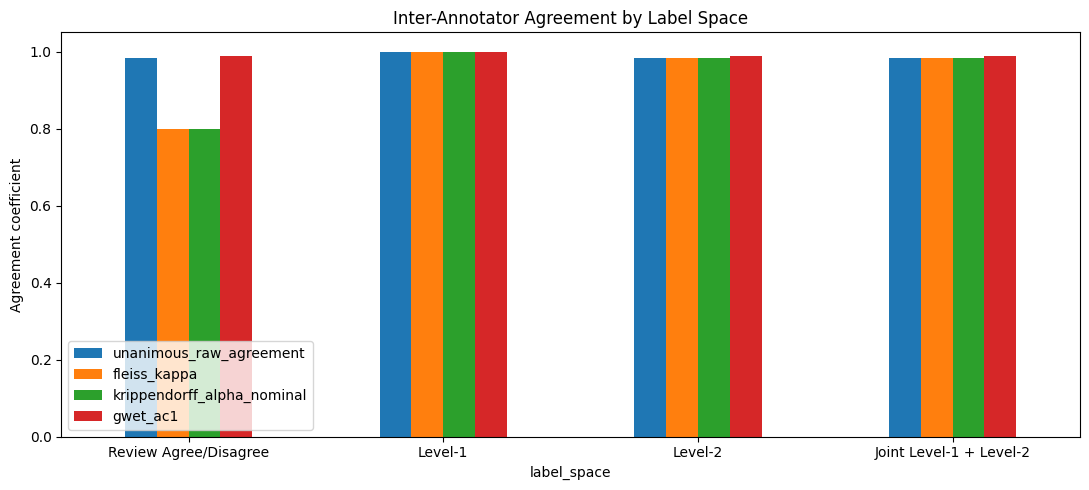

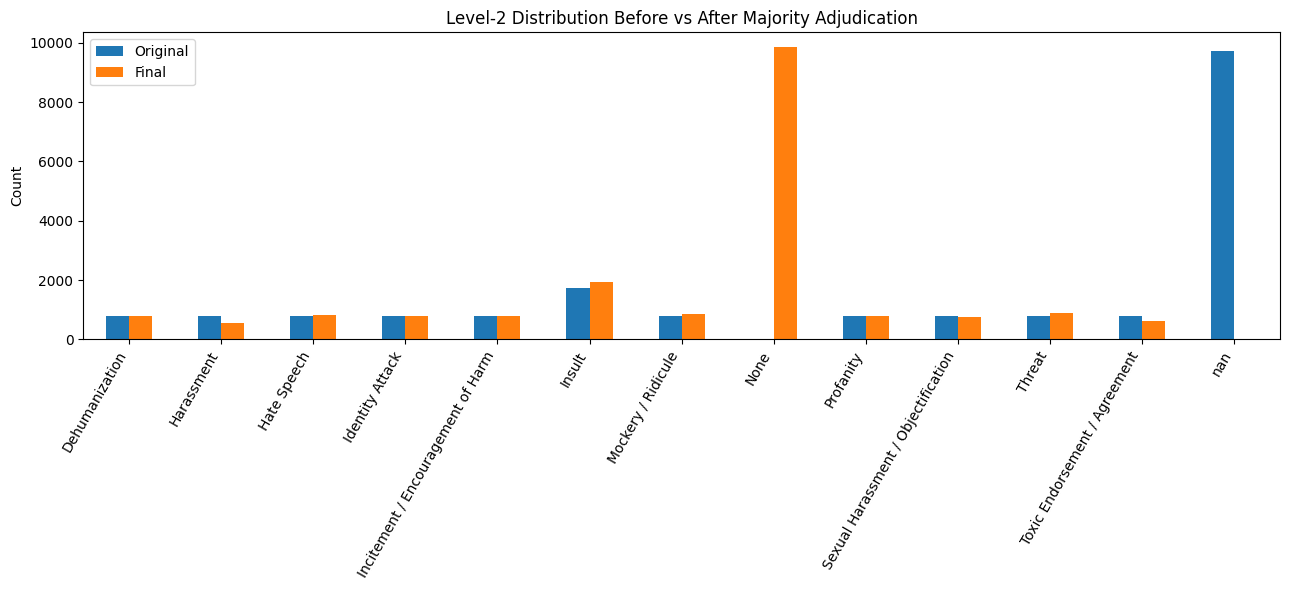

In [14]:

plot_df = iaa_summary.set_index("label_space")[
    ["unanimous_raw_agreement", "fleiss_kappa", "krippendorff_alpha_nominal", "gwet_ac1"]
]
ax = plot_df.plot(kind="bar", figsize=(11, 5))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Agreement coefficient")
ax.set_title("Inter-Annotator Agreement by Label Space")
ax.legend(loc="lower left")
plt.xticks(rotation=0)
plt.tight_layout()
fig1 = OUTPUT_DIR / "figure_iaa_metrics.png"
plt.savefig(fig1, dpi=300, bbox_inches="tight")
plt.show()

orig = df_adj[LEVEL2_COL].astype(str).value_counts()
final = df_adj["final_toxicity_type"].astype(str).value_counts()
labels = sorted(set(orig.index) | set(final.index))
counts = pd.DataFrame({
    "Original": orig.reindex(labels, fill_value=0),
    "Final": final.reindex(labels, fill_value=0),
})
ax = counts.plot(kind="bar", figsize=(13, 6))
ax.set_ylabel("Count")
ax.set_title("Level-2 Distribution Before vs After Majority Adjudication")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
fig2 = OUTPUT_DIR / "figure_level2_before_after.png"
plt.savefig(fig2, dpi=300, bbox_inches="tight")
plt.show()



## Final dataset outputs

The notebook creates:

- `final_dataset_majority_adjudicated_AUDIT.csv` — all original columns, annotator votes, and adjudication metadata.
- `final_dataset_majority_adjudicated_CLEAN.csv` — training-oriented final data. The operational `level_1_class` and `toxicity_type` columns are replaced by adjudicated labels, while the originals are retained as backup columns.
- `manual_adjudication_queue.csv` — all 3-way disagreement cases.


In [15]:
audit_path = OUTPUT_DIR / "final_dataset_majority_adjudicated_AUDIT.csv"
clean_path = OUTPUT_DIR / "final_dataset_majority_adjudicated_CLEAN.csv"
manual_path = OUTPUT_DIR / "manual_adjudication_queue.csv"

df_adj.to_csv(audit_path, index=False, encoding="utf-8-sig")

clean = original.copy().reset_index(drop=True)
clean.insert(0, "row_id", df_adj["row_id"].values)

# Canonical backups make missing Level-2 explicit as "None".
clean["original_level_1_class"] = df_adj["_original_label1_norm"].values
clean["original_toxicity_type"] = df_adj["_original_label2_norm"].values

# Operational labels become the majority-adjudicated labels.
clean[LEVEL1_COL] = df_adj["final_level_1_class"].values
clean[LEVEL2_COL] = df_adj["final_toxicity_type"].values

clean["label_changed_by_majority"] = df_adj["label_changed_by_majority"].values
clean["requires_manual_adjudication"] = df_adj["requires_manual_adjudication"].values
clean["majority_vote_count"] = df_adj["majority_vote_count"].values
clean["annotator_disagree_count"] = df_adj["annotator_disagree_count"].values

clean.to_csv(clean_path, index=False, encoding="utf-8-sig")

manual_cols = [
    "source_row_index", "row_id",
    *alignment_columns,
    "_original_label1_norm", "_original_label2_norm",
]
for i in ANNOTATOR_IDS:
    manual_cols += [
        f"annotator{i}_agree_disagree",
        f"annotator{i}_suggested_label1",
        f"annotator{i}_suggested_label2",
    ]
manual_cols += [
    "majority_vote_count",
    "annotator_disagree_count",
    "adjudication_status",
]

manual_queue = df_adj.loc[df_adj["requires_manual_adjudication"], manual_cols].copy()
manual_queue.to_csv(manual_path, index=False, encoding="utf-8-sig")

print("CLEAN:", clean_path)
print("AUDIT:", audit_path)
print("MANUAL:", manual_path)
print("Manual rows:", len(manual_queue))

CLEAN: /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/final_dataset_majority_adjudicated_CLEAN.csv
AUDIT: /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/final_dataset_majority_adjudicated_AUDIT.csv
MANUAL: /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/manual_adjudication_queue.csv
Manual rows: 1


## Final training-set preprocessing

The adjudicated dataset is now converted into a **model-training-ready** release and saved to:

`MyDrive/toxicity/final data/train/`

The cleaning policy is deliberately conservative for Bangla toxicity detection. It **does not** remove punctuation, emoji, profanity, character repetition, hashtags, URLs, or casing-like surface cues, because these can carry toxicity information.

Applied operations:

- Unicode NFC normalization;
- removal of invisible zero-width/BOM/control artifacts;
- normalization of line breaks and repeated whitespace;
- canonical `None` Level-2 label for non-toxic items;
- removal of empty target replies;
- hierarchy validation (`Non-toxic → None`, `Toxic → non-None subtype`);
- optional exclusion of unresolved 3-way adjudication cases;
- exact duplicate removal after text normalization;
- detection and exclusion of **conflicting duplicates** (identical normalized context/reply with different final labels);
- deterministic label-ID generation;
- deterministic row shuffling with the fixed study seed;
- export of excluded/problematic rows, preprocessing statistics, label maps, and file hashes.

The primary training CSV contains the normalized text and final adjudicated labels. Audit information remains available in the Q1 audit output folder.

In [16]:
# =========================
# Final training-set preprocessing
# =========================

ZERO_WIDTH_RE = re.compile(r"[\u200B\u200C\u200D\u2060\uFEFF]")
CONTROL_RE = re.compile(r"[\x00-\x08\x0B\x0C\x0E-\x1F\x7F]")
MULTISPACE_RE = re.compile(r"[ \t]+")
MULTINEWLINE_RE = re.compile(r"\n{3,}")

def normalize_bangla_text(value):
    """
    Conservative normalization for Bangla/contextual toxicity.
    Preserves punctuation, emoji, URLs, hashtags, profanity, repeated letters,
    and other potentially predictive surface features.
    """
    if pd.isna(value):
        return ""
    text = str(value)
    text = unicodedata.normalize("NFC", text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = ZERO_WIDTH_RE.sub("", text)
    text = CONTROL_RE.sub("", text)
    text = "\n".join(MULTISPACE_RE.sub(" ", line).strip() for line in text.split("\n"))
    text = MULTINEWLINE_RE.sub("\n\n", text)
    return text.strip()

# Start from the adjudicated clean dataset created above.
train_work = clean.copy()

# Preserve a row-level lineage key and normalize text fields.
for col in TEXT_COLUMNS_PREFERRED:
    if col not in train_work.columns:
        raise KeyError(f"Required text column missing from adjudicated dataset: {col}")
    train_work[col] = train_work[col].map(normalize_bangla_text)

# Canonicalize labels again at final export boundary.
train_work[LEVEL1_COL] = normalize_label1(train_work[LEVEL1_COL]).values
train_work[LEVEL2_COL] = normalize_label2(train_work[LEVEL2_COL]).values

pre_n = len(train_work)
exclusion_frames = []

# 1) Exclude rows with empty target reply.
empty_target_mask = train_work["target_reply"].str.strip().eq("")
if empty_target_mask.any():
    x = train_work.loc[empty_target_mask].copy()
    x["exclusion_reason"] = "empty_target_reply"
    exclusion_frames.append(x)
    train_work = train_work.loc[~empty_target_mask].copy()

# 2) Optionally exclude unresolved 3-way ties.
if EXCLUDE_MANUAL_ADJUDICATION and "requires_manual_adjudication" in train_work.columns:
    manual_mask = train_work["requires_manual_adjudication"].astype(bool)
    if manual_mask.any():
        x = train_work.loc[manual_mask].copy()
        x["exclusion_reason"] = "no_2of3_majority_requires_manual_adjudication"
        exclusion_frames.append(x)
        train_work = train_work.loc[~manual_mask].copy()

# 3) Enforce hierarchical label validity.
l1 = train_work[LEVEL1_COL].str.casefold()
l2 = train_work[LEVEL2_COL].str.casefold()

invalid_non_toxic = l1.eq("non-toxic") & ~l2.eq("none")
invalid_toxic = l1.eq("toxic") & l2.eq("none")
unknown_l1 = ~l1.isin(["toxic", "non-toxic"])
hierarchy_invalid = invalid_non_toxic | invalid_toxic | unknown_l1

if hierarchy_invalid.any():
    x = train_work.loc[hierarchy_invalid].copy()
    x["exclusion_reason"] = "invalid_label_hierarchy"
    exclusion_frames.append(x)
    train_work = train_work.loc[~hierarchy_invalid].copy()

# 4) Detect conflicting duplicates on the MODEL INPUT text pair.
dup_key = ["previous_reply", "target_reply"]
label_key = [LEVEL1_COL, LEVEL2_COL]

label_pair = train_work[LEVEL1_COL].astype(str) + " || " + train_work[LEVEL2_COL].astype(str)
n_unique_labels_per_text = (
    train_work.assign(_label_pair=label_pair)
    .groupby(dup_key, dropna=False)["_label_pair"]
    .transform("nunique")
)
conflict_mask = n_unique_labels_per_text.gt(1)

if DROP_CONFLICTING_DUPLICATES and conflict_mask.any():
    x = train_work.loc[conflict_mask].copy()
    x["exclusion_reason"] = "conflicting_duplicate_text_with_different_labels"
    exclusion_frames.append(x)
    train_work = train_work.loc[~conflict_mask].copy()

# 5) Drop exact same-text + same-label duplicates, keeping one deterministic row.
exact_dup_mask = train_work.duplicated(subset=dup_key + label_key, keep="first")
exact_dup_count = int(exact_dup_mask.sum())

if DROP_EXACT_DUPLICATES and exact_dup_mask.any():
    x = train_work.loc[exact_dup_mask].copy()
    x["exclusion_reason"] = "exact_duplicate_same_text_same_label"
    exclusion_frames.append(x)
    train_work = train_work.loc[~exact_dup_mask].copy()

# 6) Final hierarchy assertions.
assert train_work["target_reply"].str.len().gt(0).all()
assert (
    train_work.loc[train_work[LEVEL1_COL].eq("Non-toxic"), LEVEL2_COL].eq("None")
).all(), "Non-toxic rows must have toxicity_type=None"
assert (
    ~train_work.loc[train_work[LEVEL1_COL].eq("Toxic"), LEVEL2_COL].eq("None")
).all(), "Toxic rows must have a concrete Level-2 toxicity type"

# 7) Stable numeric label IDs.
level1_map = {"Non-toxic": 0, "Toxic": 1}
observed_l2 = sorted(train_work[LEVEL2_COL].dropna().astype(str).unique().tolist())
level2_order = ["None"] + [x for x in observed_l2 if x != "None"]
level2_map = {label: idx for idx, label in enumerate(level2_order)}

train_work["level_1_id"] = train_work[LEVEL1_COL].map(level1_map).astype("int64")
train_work["toxicity_type_id"] = train_work[LEVEL2_COL].map(level2_map).astype("int64")

# 8) Useful text-length diagnostics (Unicode code-point length, not tokenizer length).
train_work["previous_reply_char_len"] = train_work["previous_reply"].str.len().astype("int64")
train_work["target_reply_char_len"] = train_work["target_reply"].str.len().astype("int64")
train_work["previous_reply_word_len"] = train_work["previous_reply"].str.split().str.len().fillna(0).astype("int64")
train_work["target_reply_word_len"] = train_work["target_reply"].str.split().str.len().fillna(0).astype("int64")

# 9) Deterministic shuffle to avoid retaining synthetic/category block order.
if DETERMINISTIC_SHUFFLE:
    train_work = train_work.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
else:
    train_work = train_work.reset_index(drop=True)

# Keep the final training file compact and model-oriented.
preferred_final_cols = [
    "row_id",
    "previous_reply",
    "target_reply",
    LEVEL1_COL,
    LEVEL2_COL,
    "level_1_id",
    "toxicity_type_id",
    "previous_reply_char_len",
    "target_reply_char_len",
    "previous_reply_word_len",
    "target_reply_word_len",
]
final_cols = [c for c in preferred_final_cols if c in train_work.columns]
final_train = train_work[final_cols].copy()

# Excluded rows are saved separately for reproducibility/manual inspection.
if exclusion_frames:
    excluded_rows = pd.concat(exclusion_frames, ignore_index=True)
else:
    excluded_rows = pd.DataFrame(columns=list(clean.columns) + ["exclusion_reason"])

print("Rows entering preprocessing:", f"{pre_n:,}")
print("Rows in final train set    :", f"{len(final_train):,}")
print("Rows excluded              :", f"{len(excluded_rows):,}")
print("Exact duplicates detected  :", f"{exact_dup_count:,}")

print("\nFinal Level-1 distribution:")
display(final_train[LEVEL1_COL].value_counts().rename_axis("label").to_frame("count"))

print("\nFinal Level-2 distribution:")
display(final_train[LEVEL2_COL].value_counts().rename_axis("label").to_frame("count"))

Rows entering preprocessing: 19,454
Rows in final train set    : 19,453
Rows excluded              : 1
Exact duplicates detected  : 0

Final Level-1 distribution:


,count
label,
Non-toxic,9861
Toxic,9592



Final Level-2 distribution:


,count
label,
None,9861
Insult,1923
Threat,902
Mockery / Ridicule,845
Hate Speech,808
Identity Attack,800
Incitement / Encouragement of Harm,800
Dehumanization,796
Profanity,779


In [17]:
# =========================
# Save FINAL preprocessed train set
# =========================

FINAL_TRAIN_DIR.mkdir(parents=True, exist_ok=True)

final_train_path = FINAL_TRAIN_DIR / "bangla_context_toxicity_train_final_preprocessed.csv"
excluded_rows_path = FINAL_TRAIN_DIR / "excluded_rows_preprocessing_audit.csv"
label_map_path = FINAL_TRAIN_DIR / "label_mappings.json"
preprocess_report_path = FINAL_TRAIN_DIR / "preprocessing_report.json"

final_train.to_csv(final_train_path, index=False, encoding="utf-8-sig")
excluded_rows.to_csv(excluded_rows_path, index=False, encoding="utf-8-sig")

label_maps = {
    "level_1_class": level1_map,
    "toxicity_type": level2_map,
}
with open(label_map_path, "w", encoding="utf-8") as f:
    json.dump(label_maps, f, ensure_ascii=False, indent=2)

exclusion_counts = (
    excluded_rows["exclusion_reason"].value_counts().to_dict()
    if len(excluded_rows) and "exclusion_reason" in excluded_rows.columns
    else {}
)

preprocess_report = {
    "dataset_name": "Bangla contextual toxicity final preprocessed training set",
    "source_adjudicated_rows": int(pre_n),
    "final_rows": int(len(final_train)),
    "excluded_rows_total": int(len(excluded_rows)),
    "exclusion_counts": {str(k): int(v) for k, v in exclusion_counts.items()},
    "policies": {
        "unicode_normalization": "NFC",
        "remove_zero_width_and_control_artifacts": True,
        "normalize_whitespace": True,
        "aggressive_text_cleaning": False,
        "exclude_manual_adjudication": EXCLUDE_MANUAL_ADJUDICATION,
        "drop_exact_duplicates": DROP_EXACT_DUPLICATES,
        "drop_conflicting_duplicates": DROP_CONFLICTING_DUPLICATES,
        "deterministic_shuffle": DETERMINISTIC_SHUFFLE,
        "random_seed": SEED,
    },
    "level1_distribution": {
        str(k): int(v) for k, v in final_train[LEVEL1_COL].value_counts().to_dict().items()
    },
    "level2_distribution": {
        str(k): int(v) for k, v in final_train[LEVEL2_COL].value_counts().to_dict().items()
    },
    "columns": final_train.columns.tolist(),
    "destination": str(final_train_path),
}

with open(preprocess_report_path, "w", encoding="utf-8") as f:
    json.dump(preprocess_report, f, ensure_ascii=False, indent=2)

# SHA-256 for the primary final dataset (self-contained; no later-cell dependency).
def _sha256_local(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

final_train_sha256 = _sha256_local(final_train_path)

print("FINAL TRAIN DATASET SAVED:")
print(final_train_path)
print("\nSHA-256:")
print(final_train_sha256)
print("\nAdditional reproducibility files:")
print(excluded_rows_path)
print(label_map_path)
print(preprocess_report_path)

FINAL TRAIN DATASET SAVED:
/content/drive/MyDrive/toxicity/final data/train/bangla_context_toxicity_train_final_preprocessed.csv

SHA-256:
fa39d69708068ecced775bca0351100dd5626706735be1f5c0636193e9f146c0

Additional reproducibility files:
/content/drive/MyDrive/toxicity/final data/train/excluded_rows_preprocessing_audit.csv
/content/drive/MyDrive/toxicity/final data/train/label_mappings.json
/content/drive/MyDrive/toxicity/final data/train/preprocessing_report.json


In [18]:
# =========================
# Reload-from-disk validation
# =========================

reloaded_final = pd.read_csv(final_train_path, keep_default_na=False)

assert len(reloaded_final) == len(final_train)
assert reloaded_final["row_id"].is_unique, "row_id must be unique in final train set"
assert reloaded_final["target_reply"].astype(str).str.strip().ne("").all()
assert reloaded_final[LEVEL1_COL].isin(["Toxic", "Non-toxic"]).all()
assert (
    reloaded_final.loc[reloaded_final[LEVEL1_COL].eq("Non-toxic"), LEVEL2_COL].eq("None")
).all()
assert (
    reloaded_final.loc[reloaded_final[LEVEL1_COL].eq("Toxic"), LEVEL2_COL].ne("None")
).all()
assert not reloaded_final.duplicated(
    subset=["previous_reply", "target_reply", LEVEL1_COL, LEVEL2_COL]
).any()

print("✓ Final CSV reload validated")
print("✓ Unique row IDs")
print("✓ No empty target replies")
print("✓ Valid Level-1 labels")
print("✓ Hierarchical Level-1/Level-2 consistency")
print("✓ No exact text+label duplicates")
print(f"✓ Final rows: {len(reloaded_final):,}")

✓ Final CSV reload validated
✓ Unique row IDs
✓ No empty target replies
✓ Valid Level-1 labels
✓ Hierarchical Level-1/Level-2 consistency
✓ No exact text+label duplicates
✓ Final rows: 19,453


## Data in Brief / Q1 dataset characterization

This section is generated from **the saved final CSV after reload**, so paper statistics
and figures correspond exactly to the released training dataset.

It creates:

- dataset overview;
- Level-1 and Level-2 class distributions;
- previous/context and target-reply character/word length statistics;
- length histograms and subtype boxplots;
- context-length vs target-length relationship;
- Bengali/Latin code-mixing, emoji, URL, hashtag, mention and digit statistics;
- adjudication and preprocessing quality-control summaries;
- a dataset-construction workflow figure;
- CSV tables and 300-DPI PNG figures.

Outputs:

- `MyDrive/toxicity/final data/train/figures/`
- `MyDrive/toxicity/final data/train/tables/`

In [19]:
# =========================
# EDA setup
# =========================
eda = reloaded_final.copy()

for col, text_col, kind in [
    ("previous_reply_char_len", "previous_reply", "char"),
    ("target_reply_char_len", "target_reply", "char"),
    ("previous_reply_word_len", "previous_reply", "word"),
    ("target_reply_word_len", "target_reply", "word"),
]:
    if col not in eda.columns:
        if kind == "char":
            eda[col] = eda[text_col].astype(str).str.len()
        else:
            eda[col] = eda[text_col].astype(str).str.split().str.len()

BENGALI_RE = re.compile(r"[\u0980-\u09FF]")
LATIN_RE = re.compile(r"[A-Za-z]")
DIGIT_RE = re.compile(r"\d")
URL_RE = re.compile(r"(?:https?://|www\.)", re.I)
HASHTAG_RE = re.compile(r"(?<!\w)#\w+")
MENTION_RE = re.compile(r"(?<!\w)@\w+")
EMOJI_RE = re.compile(
    "["
    "\U0001F300-\U0001F5FF"
    "\U0001F600-\U0001F64F"
    "\U0001F680-\U0001F6FF"
    "\U0001F900-\U0001FAFF"
    "\u2600-\u27BF"
    "]"
)

def _has(series, pattern):
    return series.astype(str).map(lambda x: bool(pattern.search(x)))

for prefix, col in [("previous", "previous_reply"), ("target", "target_reply")]:
    s = eda[col].astype(str)
    eda[f"{prefix}_has_bengali"] = _has(s, BENGALI_RE)
    eda[f"{prefix}_has_latin"] = _has(s, LATIN_RE)
    eda[f"{prefix}_code_mixed"] = eda[f"{prefix}_has_bengali"] & eda[f"{prefix}_has_latin"]
    eda[f"{prefix}_has_digit"] = _has(s, DIGIT_RE)
    eda[f"{prefix}_has_emoji"] = _has(s, EMOJI_RE)
    eda[f"{prefix}_has_url"] = _has(s, URL_RE)
    eda[f"{prefix}_has_hashtag"] = _has(s, HASHTAG_RE)
    eda[f"{prefix}_has_mention"] = _has(s, MENTION_RE)

def save_figure(filename):
    p = FINAL_FIG_DIR / filename
    plt.savefig(p, dpi=300, bbox_inches="tight")
    print("Saved:", p)
    return p

eda_figure_paths = []
eda_table_paths = []
eda_generated_paths = []
print("EDA rows:", f"{len(eda):,}")

EDA rows: 19,453


In [20]:
# =========================
# Dataset in numbers
# =========================
n_rows = len(eda)
n_toxic = int(eda[LEVEL1_COL].eq("Toxic").sum())
n_non_toxic = int(eda[LEVEL1_COL].eq("Non-toxic").sum())
n_toxic_subtypes = int(eda.loc[eda[LEVEL1_COL].eq("Toxic"), LEVEL2_COL].nunique())

dataset_overview = pd.DataFrame([
    ["Final training rows", n_rows],
    ["Toxic rows", n_toxic],
    ["Non-toxic rows", n_non_toxic],
    ["Toxic Level-2 subtypes", n_toxic_subtypes],
    ["Unique target replies", int(eda["target_reply"].nunique())],
    ["Unique previous/context replies", int(eda["previous_reply"].nunique())],
    ["Unique context-target pairs", int(eda[["previous_reply","target_reply"]].drop_duplicates().shape[0])],
    ["Rows changed by majority", int(df_adj["label_changed_by_majority"].sum())],
    ["Rows with no majority/manual queue", int(df_adj["requires_manual_adjudication"].sum())],
    ["Rows excluded in final preprocessing", int(len(excluded_rows))],
], columns=["dataset_property", "value"])

p = FINAL_TABLE_DIR / "table_dataset_overview.csv"
dataset_overview.to_csv(p, index=False, encoding="utf-8-sig")
eda_table_paths.append(p)
display(dataset_overview)

,dataset_property,value
0,Final training rows,19453
1,Toxic rows,9592
2,Non-toxic rows,9861
3,Toxic Level-2 subtypes,11
4,Unique target replies,9514
5,Unique previous/context replies,4533
6,Unique context-target pairs,19453
7,Rows changed by majority,549
8,Rows with no majority/manual queue,1
9,Rows excluded in final preprocessing,1


Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig01_dataset_construction_pipeline.png


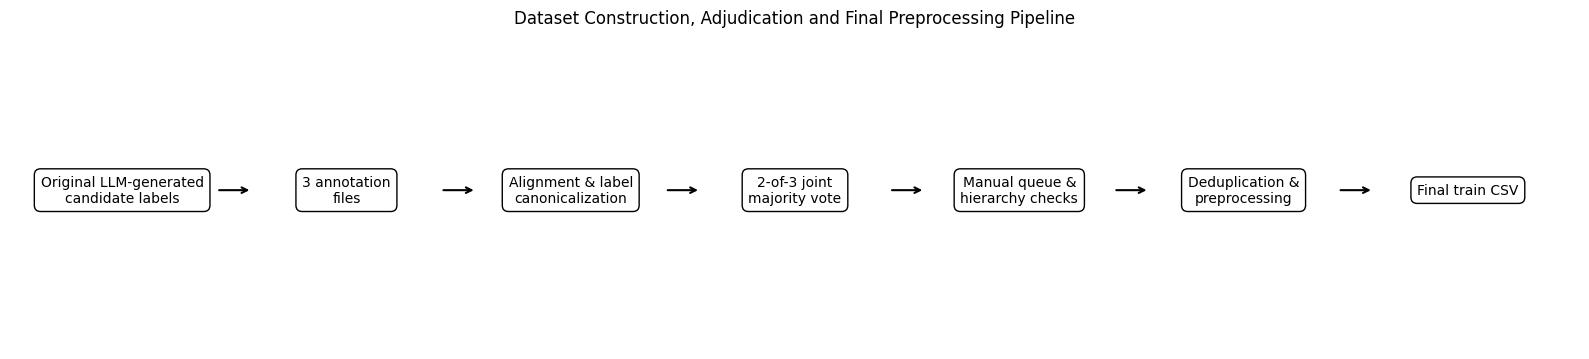

In [21]:
# =========================
# Figure 1: construction pipeline
# =========================
steps = [
    "Original LLM-generated\ncandidate labels",
    "3 annotation\nfiles",
    "Alignment & label\ncanonicalization",
    "2-of-3 joint\nmajority vote",
    "Manual queue &\nhierarchy checks",
    "Deduplication &\npreprocessing",
    "Final train CSV",
]

plt.figure(figsize=(16, 3.7))
ax = plt.gca()
ax.set_xlim(0, len(steps))
ax.set_ylim(0, 1)
ax.axis("off")

for i, txt in enumerate(steps):
    x = i + 0.5
    ax.text(x, 0.5, txt, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.45", fill=False))
    if i < len(steps)-1:
        ax.annotate("", xy=(i+1.08, 0.5), xytext=(i+0.92, 0.5),
                    arrowprops=dict(arrowstyle="->", linewidth=1.5))

plt.title("Dataset Construction, Adjudication and Final Preprocessing Pipeline")
plt.tight_layout()
p = save_figure("fig01_dataset_construction_pipeline.png")
eda_figure_paths.append(p)
plt.show()

,level_1_class,count,percentage
0,Non-toxic,9861,50.69141
1,Toxic,9592,49.30859


Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig02_level1_class_distribution.png


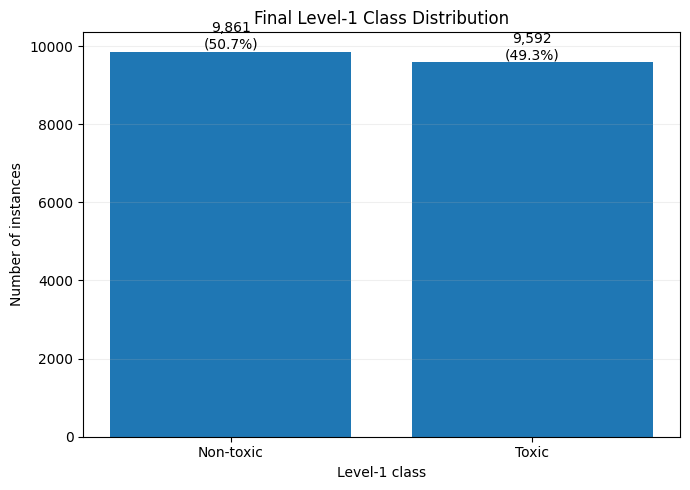

In [22]:
# =========================
# Figure 2: Level-1 class distribution
# =========================
l1_counts = eda[LEVEL1_COL].value_counts().rename_axis("level_1_class").reset_index(name="count")
l1_counts["percentage"] = 100 * l1_counts["count"] / len(eda)

p = FINAL_TABLE_DIR / "table_level1_class_distribution.csv"
l1_counts.to_csv(p, index=False, encoding="utf-8-sig")
eda_table_paths.append(p)
display(l1_counts)

plt.figure(figsize=(7,5))
bars = plt.bar(l1_counts["level_1_class"], l1_counts["count"])
plt.xlabel("Level-1 class")
plt.ylabel("Number of instances")
plt.title("Final Level-1 Class Distribution")
plt.grid(axis="y", alpha=0.2)
for bar, count, pct in zip(bars, l1_counts["count"], l1_counts["percentage"]):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height(),
             f"{count:,}\n({pct:.1f}%)", ha="center", va="bottom")
plt.tight_layout()
p = save_figure("fig02_level1_class_distribution.png")
eda_figure_paths.append(p)
plt.show()

,toxicity_type,count,percentage_within_toxic
0,Insult,1923,20.047957
1,Threat,902,9.403670
2,Mockery / Ridicule,845,8.809425
3,Hate Speech,808,8.423686
4,Identity Attack,800,8.340284
5,Incitement / Encouragement of Harm,800,8.340284
6,Dehumanization,796,8.298582
7,Profanity,779,8.121351
8,Sexual Harassment / Objectification,763,7.954545
9,Toxic Endorsement / Agreement,621,6.474145


Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig03_level2_toxic_subtype_distribution.png


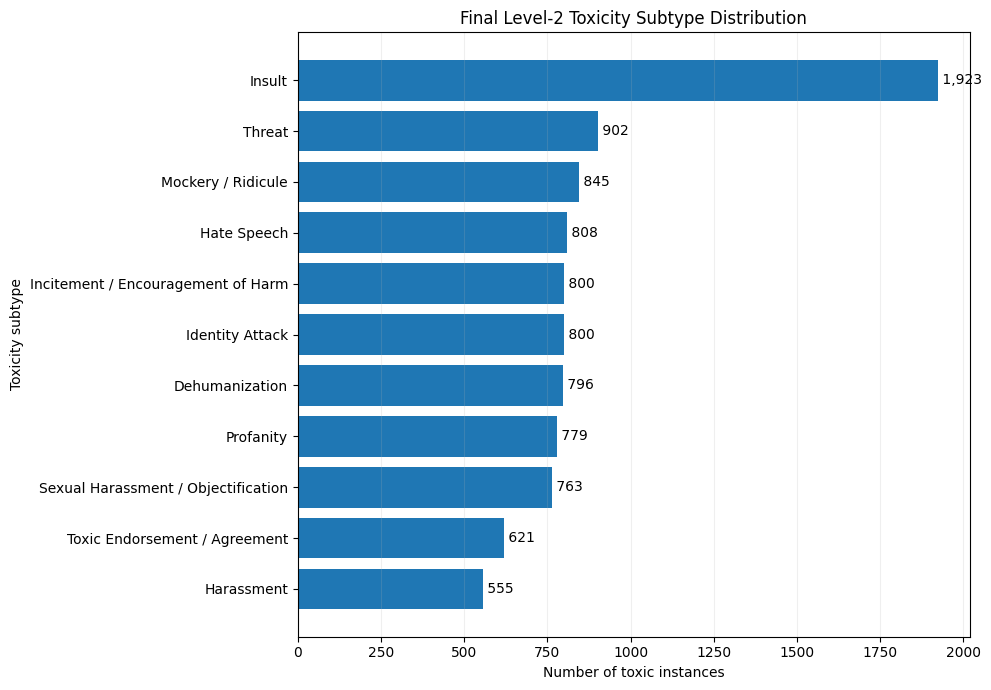

In [23]:
# =========================
# Figure 3: Level-2 toxic subtype distribution
# =========================
toxic_only = eda.loc[eda[LEVEL1_COL].eq("Toxic")].copy()
l2_counts = toxic_only[LEVEL2_COL].value_counts().rename_axis("toxicity_type").reset_index(name="count")
l2_counts["percentage_within_toxic"] = 100 * l2_counts["count"] / len(toxic_only)

p = FINAL_TABLE_DIR / "table_level2_toxic_subtype_distribution.csv"
l2_counts.to_csv(p, index=False, encoding="utf-8-sig")
eda_table_paths.append(p)
display(l2_counts)

plot_l2 = l2_counts.sort_values("count")
plt.figure(figsize=(10,7))
bars = plt.barh(plot_l2["toxicity_type"], plot_l2["count"])
plt.xlabel("Number of toxic instances")
plt.ylabel("Toxicity subtype")
plt.title("Final Level-2 Toxicity Subtype Distribution")
plt.grid(axis="x", alpha=0.2)
for bar, count in zip(bars, plot_l2["count"]):
    plt.text(bar.get_width(), bar.get_y()+bar.get_height()/2, f" {count:,}", va="center")
plt.tight_layout()
p = save_figure("fig03_level2_toxic_subtype_distribution.png")
eda_figure_paths.append(p)
plt.show()

In [24]:
# =========================
# Reply length descriptive statistics
# =========================
length_cols = [
    "previous_reply_char_len",
    "previous_reply_word_len",
    "target_reply_char_len",
    "target_reply_word_len",
]

def describe_lengths(frame, group_name):
    rows = []
    for col in length_cols:
        s = pd.to_numeric(frame[col], errors="coerce").dropna()
        rows.append({
            "group": group_name,
            "measure": col,
            "count": int(s.count()),
            "mean": float(s.mean()),
            "std": float(s.std()),
            "min": float(s.min()),
            "q25": float(s.quantile(.25)),
            "median": float(s.median()),
            "q75": float(s.quantile(.75)),
            "p95": float(s.quantile(.95)),
            "max": float(s.max()),
        })
    return pd.DataFrame(rows)

length_overall = describe_lengths(eda, "Overall")
length_by_l1 = pd.concat(
    [describe_lengths(g, label) for label, g in eda.groupby(LEVEL1_COL)],
    ignore_index=True
)
length_by_l2 = pd.concat(
    [describe_lengths(g, label) for label, g in toxic_only.groupby(LEVEL2_COL)],
    ignore_index=True
)

for name, table in [
    ("table_reply_length_statistics_overall.csv", length_overall),
    ("table_reply_length_statistics_by_level1.csv", length_by_l1),
    ("table_reply_length_statistics_by_level2_toxic.csv", length_by_l2),
]:
    p = FINAL_TABLE_DIR / name
    table.to_csv(p, index=False)
    eda_table_paths.append(p)

display(length_overall)
display(length_by_l1)

,group,measure,count,mean,std,min,q25,median,q75,p95,max
0,Overall,previous_reply_char_len,19453,45.463116,15.563071,10.0,34.0,44.0,55.0,72.0,220.0
1,Overall,previous_reply_word_len,19453,7.545880,2.764083,2.0,5.0,7.0,9.0,13.0,39.0
2,Overall,target_reply_char_len,19453,62.789236,23.016241,4.0,50.0,61.0,73.0,92.0,666.0
3,Overall,target_reply_word_len,19453,10.825220,3.953239,1.0,9.0,11.0,12.0,16.0,115.0


,group,measure,count,mean,std,min,q25,median,q75,p95,max
0,Non-toxic,previous_reply_char_len,9861,50.607342,14.956657,18.0,41.0,50.0,60.0,74.0,220.0
1,Non-toxic,previous_reply_word_len,9861,8.420039,2.556426,3.0,7.0,8.0,10.0,13.0,39.0
2,Non-toxic,target_reply_char_len,9861,64.038840,17.583692,4.0,51.0,63.0,77.0,92.0,203.0
3,Non-toxic,target_reply_word_len,9861,10.848798,2.919952,1.0,9.0,11.0,13.0,16.0,37.0
4,Toxic,previous_reply_char_len,9592,40.174625,14.355557,10.0,30.0,37.0,47.0,64.0,171.0
5,Toxic,previous_reply_word_len,9592,6.647206,2.680190,2.0,5.0,6.0,8.0,12.0,26.0
6,Toxic,target_reply_char_len,9592,61.504587,27.446200,4.0,50.0,59.0,69.0,91.0,666.0
7,Toxic,target_reply_word_len,9592,10.800980,4.788500,1.0,9.0,10.0,12.0,16.0,115.0


Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig04_target_reply_character_length_by_level1.png


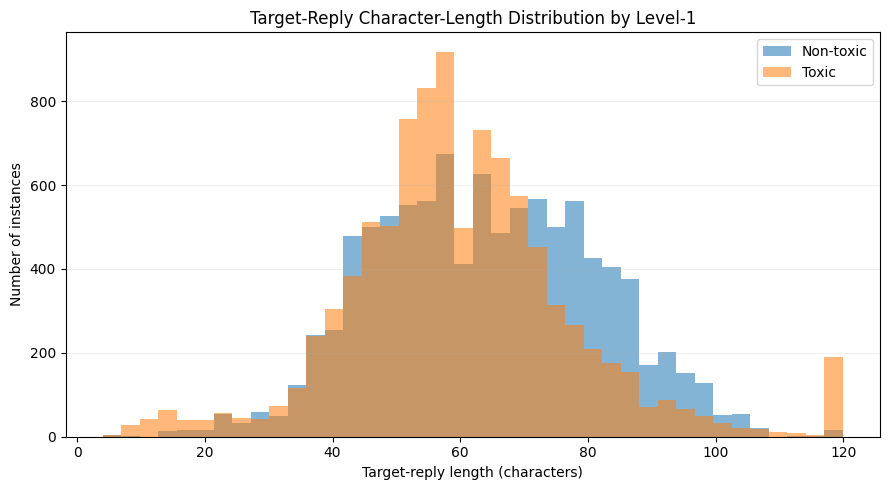

Visualization-only 99th percentile cap: 119.95999999999913


In [25]:
# =========================
# Figure 4: target character length
# =========================
cap = float(eda["target_reply_char_len"].quantile(.99))
plt.figure(figsize=(9,5))
for label in ["Non-toxic", "Toxic"]:
    vals = eda.loc[eda[LEVEL1_COL].eq(label), "target_reply_char_len"].clip(upper=cap)
    plt.hist(vals, bins=40, alpha=.55, label=label)
plt.xlabel("Target-reply length (characters)")
plt.ylabel("Number of instances")
plt.title("Target-Reply Character-Length Distribution by Level-1")
plt.legend()
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
p = save_figure("fig04_target_reply_character_length_by_level1.png")
eda_figure_paths.append(p)
plt.show()
print("Visualization-only 99th percentile cap:", cap)

Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig05_target_reply_word_length_by_level1.png


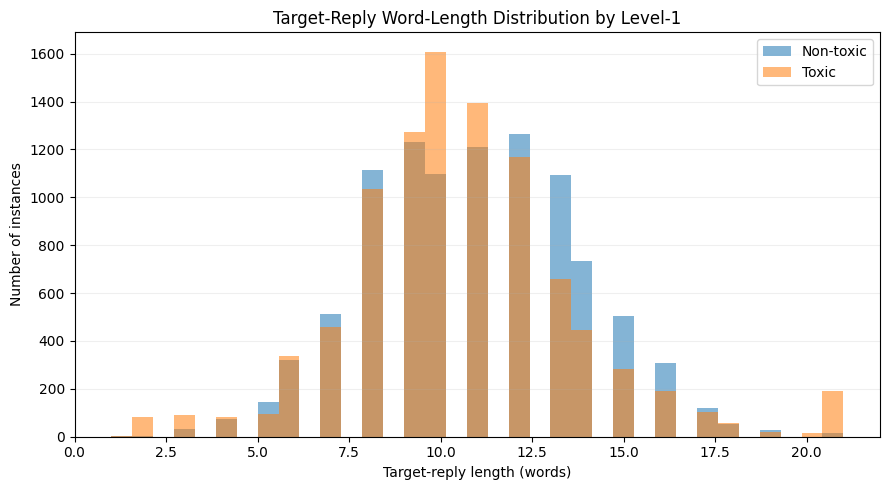

In [26]:
# =========================
# Figure 5: target word length
# =========================
cap = float(eda["target_reply_word_len"].quantile(.99))
plt.figure(figsize=(9,5))
for label in ["Non-toxic", "Toxic"]:
    vals = eda.loc[eda[LEVEL1_COL].eq(label), "target_reply_word_len"].clip(upper=cap)
    plt.hist(vals, bins=35, alpha=.55, label=label)
plt.xlabel("Target-reply length (words)")
plt.ylabel("Number of instances")
plt.title("Target-Reply Word-Length Distribution by Level-1")
plt.legend()
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
p = save_figure("fig05_target_reply_word_length_by_level1.png")
eda_figure_paths.append(p)
plt.show()

Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig06_previous_reply_character_length.png


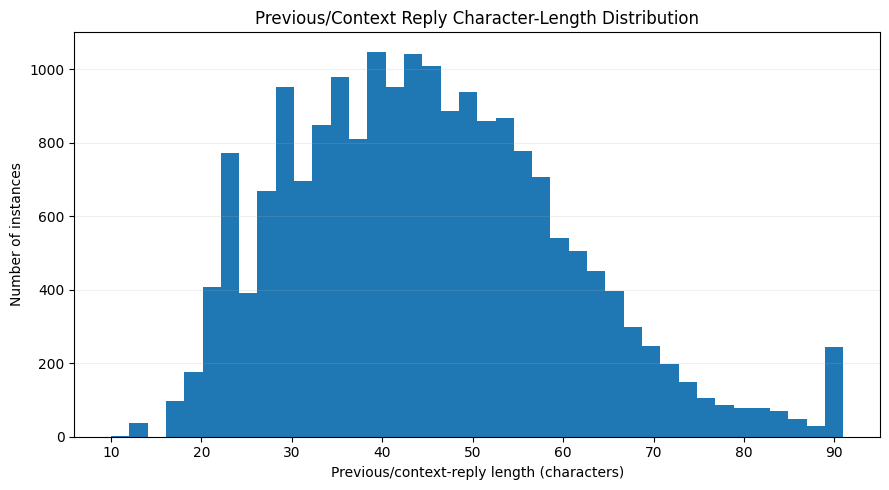

In [27]:
# =========================
# Figure 6: context character length
# =========================
cap = float(eda["previous_reply_char_len"].quantile(.99))
plt.figure(figsize=(9,5))
plt.hist(eda["previous_reply_char_len"].clip(upper=cap), bins=40)
plt.xlabel("Previous/context-reply length (characters)")
plt.ylabel("Number of instances")
plt.title("Previous/Context Reply Character-Length Distribution")
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
p = save_figure("fig06_previous_reply_character_length.png")
eda_figure_paths.append(p)
plt.show()

/tmp/ipykernel_1482/2644636568.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=order, showfliers=False)


Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig07_target_word_length_by_toxic_subtype_boxplot.png


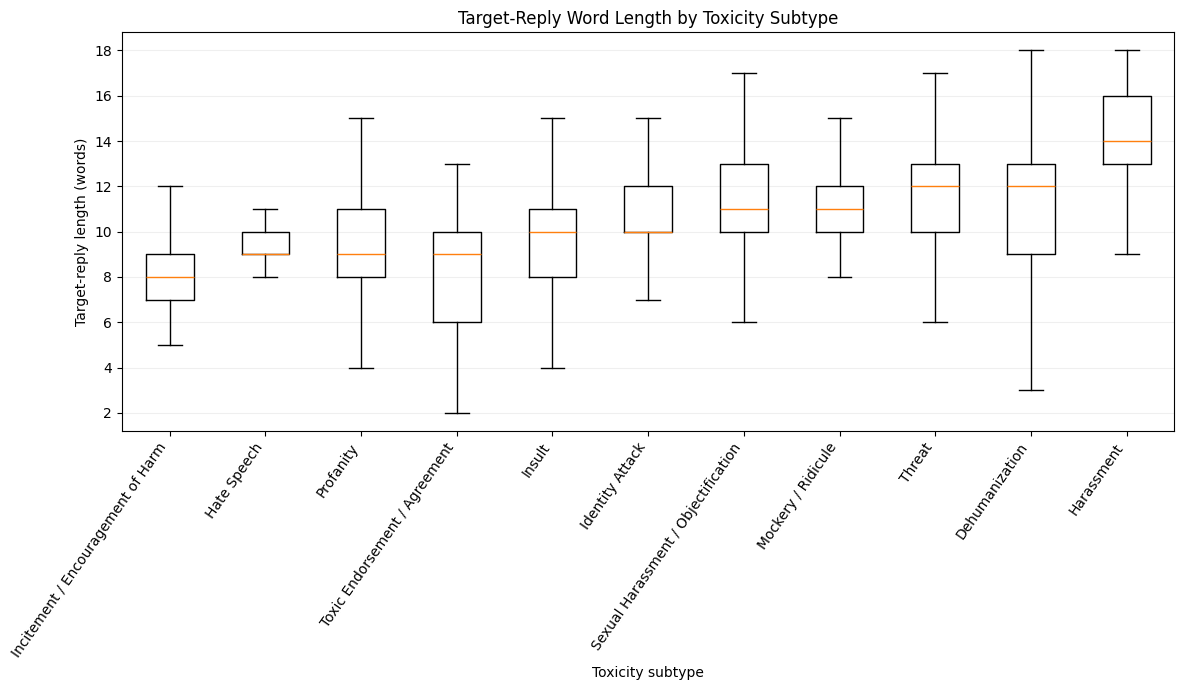

In [28]:
# =========================
# Figure 7: subtype-wise target word length
# =========================
order = toxic_only.groupby(LEVEL2_COL)["target_reply_word_len"].median().sort_values().index.tolist()
box_data = [
    toxic_only.loc[toxic_only[LEVEL2_COL].eq(label), "target_reply_word_len"].to_numpy()
    for label in order
]
plt.figure(figsize=(12,7))
plt.boxplot(box_data, labels=order, showfliers=False)
plt.xlabel("Toxicity subtype")
plt.ylabel("Target-reply length (words)")
plt.title("Target-Reply Word Length by Toxicity Subtype")
plt.xticks(rotation=55, ha="right")
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
p = save_figure("fig07_target_word_length_by_toxic_subtype_boxplot.png")
eda_figure_paths.append(p)
plt.show()

Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig08_context_vs_target_word_length.png


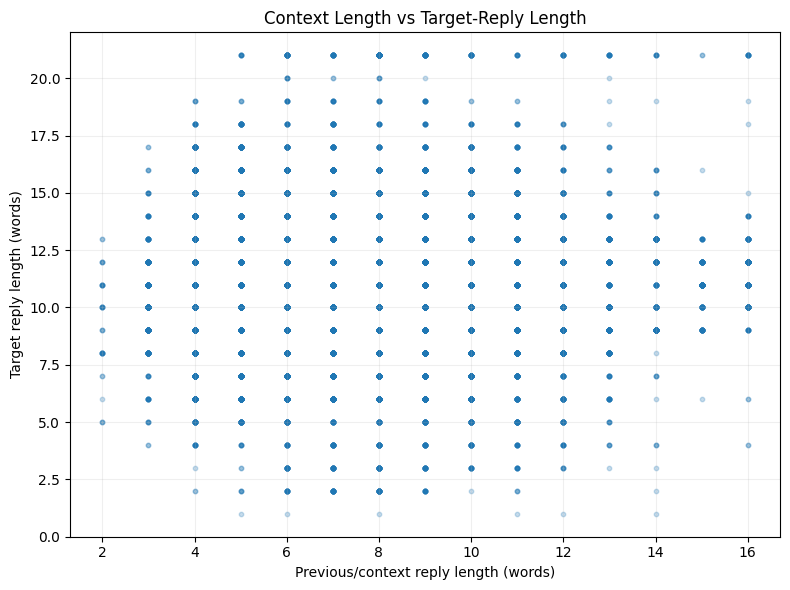

,pearson_correlation,spearman_correlation
0,0.052537,0.024296


In [29]:
# =========================
# Figure 8: context vs target word length
# =========================
x = eda["previous_reply_word_len"].astype(float)
y = eda["target_reply_word_len"].astype(float)
xcap, ycap = float(x.quantile(.99)), float(y.quantile(.99))

plt.figure(figsize=(8,6))
plt.scatter(x.clip(upper=xcap), y.clip(upper=ycap), s=10, alpha=.25)
plt.xlabel("Previous/context reply length (words)")
plt.ylabel("Target reply length (words)")
plt.title("Context Length vs Target-Reply Length")
plt.grid(alpha=.2)
plt.tight_layout()
p = save_figure("fig08_context_vs_target_word_length.png")
eda_figure_paths.append(p)
plt.show()

corr = pd.DataFrame([{
    "pearson_correlation": float(eda[["previous_reply_word_len","target_reply_word_len"]].corr("pearson").iloc[0,1]),
    "spearman_correlation": float(eda[["previous_reply_word_len","target_reply_word_len"]].corr("spearman").iloc[0,1]),
}])
p = FINAL_TABLE_DIR / "table_context_target_length_correlation.csv"
corr.to_csv(p, index=False)
eda_table_paths.append(p)
display(corr)

,text_field,characteristic,count,percentage
0,Previous/context reply,Contains Bengali script,19453,100.000000
1,Previous/context reply,Contains Latin script,42,0.215905
2,Previous/context reply,Bangla-English code-mixed,42,0.215905
3,Previous/context reply,Contains emoji/symbol,0,0.000000
4,Previous/context reply,Contains digit,0,0.000000
5,Previous/context reply,Contains URL,0,0.000000
6,Previous/context reply,Contains hashtag,0,0.000000
7,Previous/context reply,Contains @mention,0,0.000000
8,Target reply,Contains Bengali script,19451,99.989719
9,Target reply,Contains Latin script,27,0.138796


Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig09_text_characteristics.png


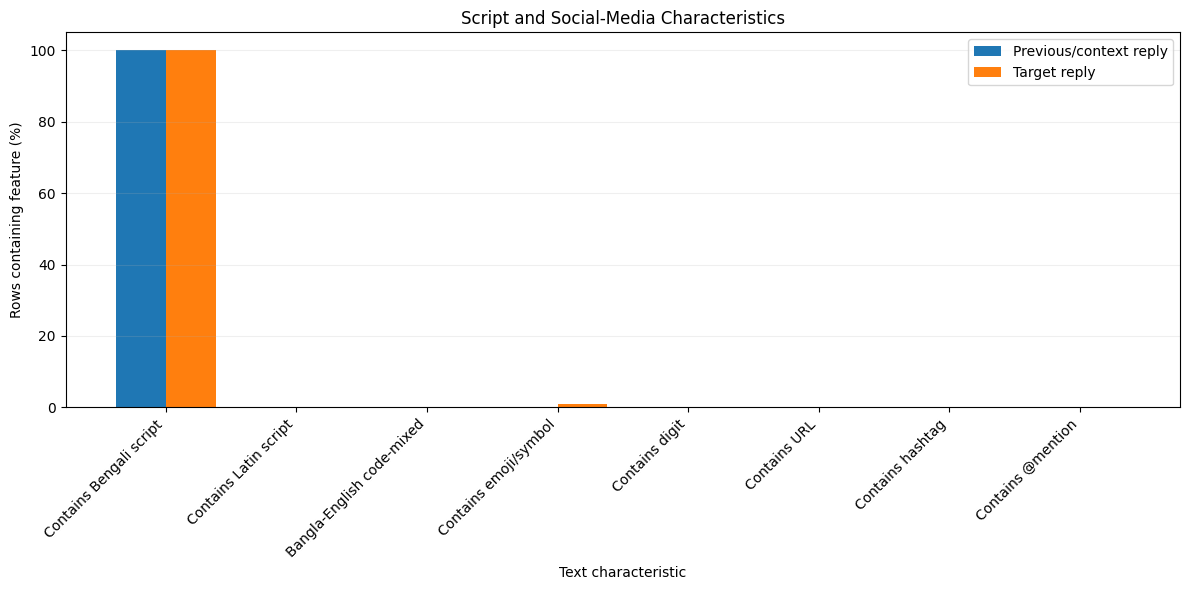

In [30]:
# =========================
# Figure 9: text characteristics
# =========================
features = [
    ("Contains Bengali script", "has_bengali"),
    ("Contains Latin script", "has_latin"),
    ("Bangla-English code-mixed", "code_mixed"),
    ("Contains emoji/symbol", "has_emoji"),
    ("Contains digit", "has_digit"),
    ("Contains URL", "has_url"),
    ("Contains hashtag", "has_hashtag"),
    ("Contains @mention", "has_mention"),
]

rows = []
for field, prefix in [("Previous/context reply","previous"), ("Target reply","target")]:
    for name, suffix in features:
        count = int(eda[f"{prefix}_{suffix}"].sum())
        rows.append({
            "text_field": field,
            "characteristic": name,
            "count": count,
            "percentage": 100*count/len(eda)
        })

text_characteristics = pd.DataFrame(rows)
p = FINAL_TABLE_DIR / "table_text_characteristics.csv"
text_characteristics.to_csv(p, index=False, encoding="utf-8-sig")
eda_table_paths.append(p)
display(text_characteristics)

wide = text_characteristics.pivot(index="characteristic", columns="text_field", values="percentage")
wide = wide.reindex([x[0] for x in features])
xpos = np.arange(len(wide))
width = .38

plt.figure(figsize=(12,6))
plt.bar(xpos-width/2, wide["Previous/context reply"], width, label="Previous/context reply")
plt.bar(xpos+width/2, wide["Target reply"], width, label="Target reply")
plt.ylabel("Rows containing feature (%)")
plt.xlabel("Text characteristic")
plt.title("Script and Social-Media Characteristics")
plt.xticks(xpos, wide.index, rotation=45, ha="right")
plt.legend()
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
p = save_figure("fig09_text_characteristics.png")
eda_figure_paths.append(p)
plt.show()

,outcome,count,percentage
0,Unchanged by majority,18904,97.172818
1,Changed by majority,549,2.822042
2,No majority / manual,1,0.005140


Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig10_adjudication_outcome.png


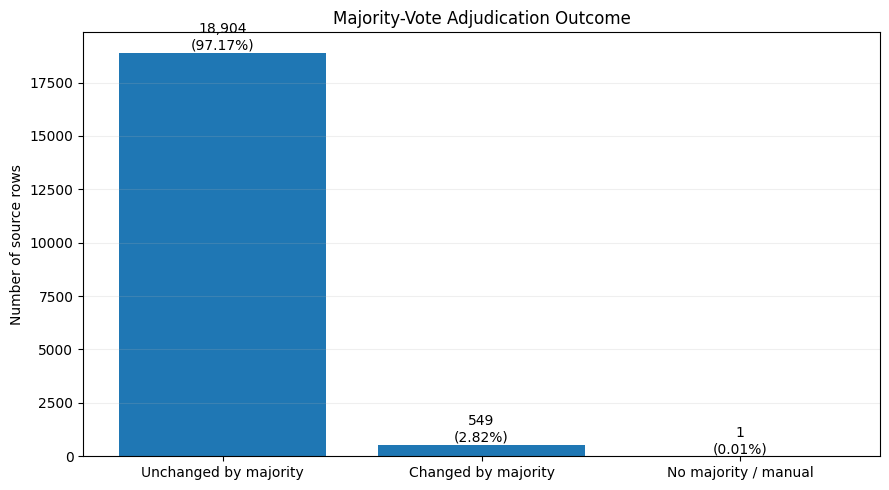

In [31]:
# =========================
# Figure 10: adjudication outcome
# =========================
adjudication_outcome = pd.DataFrame([
    ["Unchanged by majority", int(df_adj["has_majority_consensus"].sum() - df_adj["label_changed_by_majority"].sum())],
    ["Changed by majority", int(df_adj["label_changed_by_majority"].sum())],
    ["No majority / manual", int(df_adj["requires_manual_adjudication"].sum())],
], columns=["outcome","count"])
adjudication_outcome["percentage"] = 100*adjudication_outcome["count"]/len(df_adj)

p = FINAL_TABLE_DIR / "table_adjudication_outcome.csv"
adjudication_outcome.to_csv(p, index=False)
eda_table_paths.append(p)
display(adjudication_outcome)

plt.figure(figsize=(9,5))
bars = plt.bar(adjudication_outcome["outcome"], adjudication_outcome["count"])
plt.ylabel("Number of source rows")
plt.title("Majority-Vote Adjudication Outcome")
plt.grid(axis="y", alpha=.2)
for bar, count, pct in zip(bars, adjudication_outcome["count"], adjudication_outcome["percentage"]):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height(),
             f"{count:,}\n({pct:.2f}%)", ha="center", va="bottom")
plt.tight_layout()
p = save_figure("fig10_adjudication_outcome.png")
eda_figure_paths.append(p)
plt.show()

,status,count,percentage
0,Retained in final train,19453,99.99486
1,Excluded in preprocessing,1,0.00514


Saved: /content/drive/MyDrive/toxicity/final data/train/figures/fig11_preprocessing_retention.png


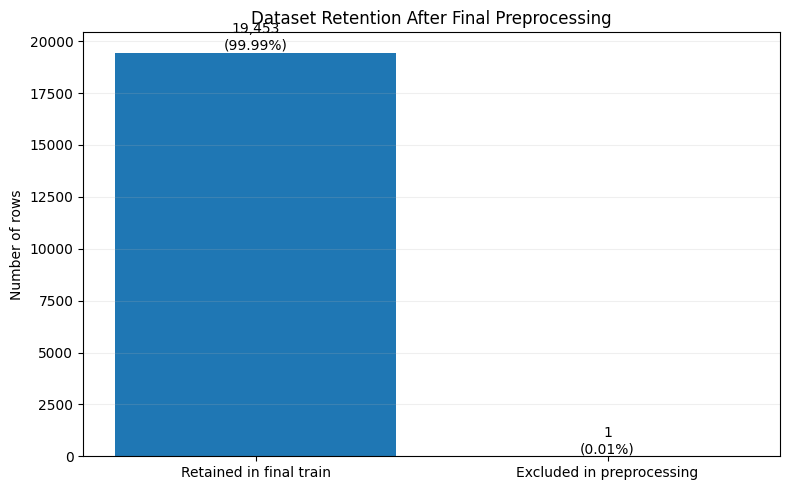

,exclusion_reason,count
0,no_2of3_majority_requires_manual_adjudication,1


In [32]:
# =========================
# Figure 11: preprocessing retention
# =========================
retention = pd.DataFrame([
    ["Retained in final train", int(len(final_train))],
    ["Excluded in preprocessing", int(len(excluded_rows))],
], columns=["status","count"])
retention["percentage"] = 100*retention["count"]/retention["count"].sum()

p = FINAL_TABLE_DIR / "table_preprocessing_retention.csv"
retention.to_csv(p, index=False)
eda_table_paths.append(p)
display(retention)

plt.figure(figsize=(8,5))
bars = plt.bar(retention["status"], retention["count"])
plt.ylabel("Number of rows")
plt.title("Dataset Retention After Final Preprocessing")
plt.grid(axis="y", alpha=.2)
for bar, count, pct in zip(bars, retention["count"], retention["percentage"]):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height(),
             f"{count:,}\n({pct:.2f}%)", ha="center", va="bottom")
plt.tight_layout()
p = save_figure("fig11_preprocessing_retention.png")
eda_figure_paths.append(p)
plt.show()

if len(excluded_rows) and "exclusion_reason" in excluded_rows.columns:
    exclusion_reasons = excluded_rows["exclusion_reason"].value_counts().rename_axis("exclusion_reason").reset_index(name="count")
else:
    exclusion_reasons = pd.DataFrame([["None",0]], columns=["exclusion_reason","count"])

p = FINAL_TABLE_DIR / "table_preprocessing_exclusion_reasons.csv"
exclusion_reasons.to_csv(p, index=False)
eda_table_paths.append(p)
display(exclusion_reasons)

In [33]:
# =========================
# Paper-ready dataset-characterization summary
# =========================
toxic_pct = 100*n_toxic/n_rows
non_toxic_pct = 100*n_non_toxic/n_rows

data_brief_text = f'''
DATASET CHARACTERIZATION

The final preprocessed release contains {n_rows:,} context-target reply pairs.
At Level-1, {n_toxic:,} instances ({toxic_pct:.2f}%) are Toxic and
{n_non_toxic:,} ({non_toxic_pct:.2f}%) are Non-toxic. Toxic examples span
{n_toxic_subtypes} Level-2 toxicity subtypes.

Previous/context replies have a median of
{eda["previous_reply_word_len"].median():.0f} words
(mean {eda["previous_reply_word_len"].mean():.2f}), while target replies have a median
of {eda["target_reply_word_len"].median():.0f} words
(mean {eda["target_reply_word_len"].mean():.2f}).

Median character lengths are {eda["previous_reply_char_len"].median():.0f}
for previous/context replies and {eda["target_reply_char_len"].median():.0f}
for target replies.

The released final CSV was reloaded from disk before descriptive analysis. The workflow
uses conservative normalization and preserves punctuation, emoji, URLs, hashtags,
profanity and character repetition.

Annotation provenance for this run: {ANNOTATOR_PROVENANCE}.
'''.strip()

summary_path = FINAL_TABLE_DIR / "data_in_brief_dataset_characterization.txt"
summary_path.write_text(data_brief_text, encoding="utf-8")
eda_table_paths.append(summary_path)

figure_manifest = pd.DataFrame(
    [{"figure_file": Path(p).name, "path": str(p)} for p in eda_figure_paths]
).sort_values("figure_file")
figure_manifest_path = FINAL_TABLE_DIR / "figure_manifest.csv"
figure_manifest.to_csv(figure_manifest_path, index=False)
eda_table_paths.append(figure_manifest_path)

table_manifest_path = FINAL_TABLE_DIR / "table_manifest.csv"
pd.DataFrame(
    [{"table_file": Path(p).name, "path": str(p)} for p in eda_table_paths]
).drop_duplicates().to_csv(table_manifest_path, index=False)

eda_generated_paths = list(dict.fromkeys(
    [Path(p) for p in eda_figure_paths]
    + [Path(p) for p in eda_table_paths]
    + [figure_manifest_path, table_manifest_path]
))

print(data_brief_text)
print("\nFigures generated:", len(eda_figure_paths))
print("Figure directory:", FINAL_FIG_DIR)
print("Table directory:", FINAL_TABLE_DIR)

DATASET CHARACTERIZATION

The final preprocessed release contains 19,453 context-target reply pairs.
At Level-1, 9,592 instances (49.31%) are Toxic and
9,861 (50.69%) are Non-toxic. Toxic examples span
11 Level-2 toxicity subtypes.

Previous/context replies have a median of
7 words
(mean 7.55), while target replies have a median
of 11 words
(mean 10.83).

Median character lengths are 44
for previous/context replies and 61
for target replies.

The released final CSV was reloaded from disk before descriptive analysis. The workflow
uses conservative normalization and preserves punctuation, emoji, URLs, hashtags,
profanity and character repetition.

Annotation provenance for this run: annotators.

Figures generated: 11
Figure directory: /content/drive/MyDrive/toxicity/final data/train/figures
Table directory: /content/drive/MyDrive/toxicity/final data/train/tables


In [34]:
iaa_path = OUTPUT_DIR / "iaa_summary.csv"
boot_path = OUTPUT_DIR / "iaa_bootstrap_95ci.csv"
pairwise_path = OUTPUT_DIR / "pairwise_iaa.csv"
prevalence_path = OUTPUT_DIR / "annotator_label_prevalence.csv"
distribution_path = OUTPUT_DIR / "label_distribution_before_after.csv"
disagreement_pairs_path = OUTPUT_DIR / "level2_disagreement_pairs.csv"

iaa_summary.to_csv(iaa_path, index=False)
bootstrap_ci_table.to_csv(boot_path, index=False)
pairwise_iaa.to_csv(pairwise_path, index=False)
label_prevalence.to_csv(prevalence_path, index=False)
label_distribution.to_csv(distribution_path, index=False)
level2_disagreement_pairs.to_csv(disagreement_pairs_path, index=False)

print("Journal tables saved:")
for p in [
    iaa_path, boot_path, pairwise_path, prevalence_path,
    distribution_path, disagreement_pairs_path
]:
    print(" -", p)

Journal tables saved:
 - /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/iaa_summary.csv
 - /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/iaa_bootstrap_95ci.csv
 - /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/pairwise_iaa.csv
 - /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/annotator_label_prevalence.csv
 - /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/label_distribution_before_after.csv
 - /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/level2_disagreement_pairs.csv


In [35]:

def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

source_paths = [ORIGINAL_CSV] + [annotator_files[i] for i in ANNOTATOR_IDS]
generated_paths = [
    audit_path, clean_path, manual_path,
    iaa_path, boot_path, pairwise_path, prevalence_path, distribution_path,
    fig1, fig2, disagreement_pairs_path,
    final_train_path, excluded_rows_path, label_map_path, preprocess_report_path,
] + list(eda_generated_paths)

hash_rows = []
for kind, paths in [("source", source_paths), ("generated", generated_paths)]:
    for p in paths:
        p = Path(p)
        if p.exists():
            hash_rows.append({
                "kind": kind,
                "filename": p.name,
                "path": str(p),
                "size_bytes": p.stat().st_size,
                "sha256": sha256_file(p),
            })

hash_table = pd.DataFrame(hash_rows)
hash_path = OUTPUT_DIR / "file_hashes_sha256.csv"
hash_table.to_csv(hash_path, index=False)

manifest = {
    "study_component": "Annotation agreement and majority-vote adjudication",
    "annotator_provenance": ANNOTATOR_PROVENANCE,
    "final_training_dataset": str(final_train_path),
    "final_training_sha256": final_train_sha256,
    "final_training_rows": int(len(final_train)),
    "preprocessing_report": str(preprocess_report_path),
    "data_in_brief_figure_directory": str(FINAL_FIG_DIR),
    "data_in_brief_table_directory": str(FINAL_TABLE_DIR),
    "data_in_brief_figures": int(len(eda_figure_paths)),
    "random_seed": SEED,
    "n_bootstrap": N_BOOT,
    "bootstrap_ci": BOOT_CI,
    "n_rows": int(len(df_adj)),
    "n_annotators": 3,
    "original_csv": str(ORIGINAL_CSV),
    "annotator_files": {str(i): str(p) for i, p in annotator_files.items()},
    "alignment_columns": alignment_columns,
    "level1_column": LEVEL1_COL,
    "level2_column": LEVEL2_COL,
    "adjudication_rule": (
        "Exact joint (Level-1, Level-2) majority vote across 3 annotators. "
        "2/3 or 3/3 consensus accepted; no-majority rows retained original labels "
        "and flagged for manual adjudication."
    ),
    "summary": summary,
    "software": {
        "python": sys.version,
        "platform": platform.platform(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}

manifest_path = OUTPUT_DIR / "reproducibility_manifest.json"
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

print("Saved:", hash_path)
print("Saved:", manifest_path)


Saved: /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/file_hashes_sha256.csv
Saved: /content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs/reproducibility_manifest.json


In [36]:
def pct(x):
    return f"{100*x:.2f}%"

def metric_from(space, col):
    return float(iaa_summary.loc[iaa_summary["label_space"] == space, col].iloc[0])

methods_text = f'''
ANNOTATION AGREEMENT AND ADJUDICATION

Three independent annotation files were analyzed under the provenance setting:
"{ANNOTATOR_PROVENANCE}".

Each file contained an Agree/Disagree decision relative to the original machine-generated
annotation and a complete suggested Level-1 and Level-2 label. Before analysis, missing
Level-2 values (blank/NaN/None) were canonicalized to the explicit category "None".
Final automatic adjudication used an exact joint-label majority vote. A label was
accepted when at least two of three annotators selected the same (Level-1, Level-2)
pair. Cases without a 2/3 majority were not force-resolved; the original canonical
label was retained provisionally and the item was flagged for manual adjudication.

Agreement was assessed for the review decision, Level-1, Level-2, and the joint
hierarchical label using unanimous raw agreement, pairwise percent agreement,
pairwise Cohen's kappa, Fleiss' kappa, Krippendorff's alpha (nominal), and Gwet's AC1.
Bootstrap {int(BOOT_CI*100)}% confidence intervals were estimated using {N_BOOT:,}
item-level bootstrap resamples with random seed {SEED}.

DATASET ADJUDICATION SUMMARY
Total items: {len(df_adj):,}
3/3 unanimous joint-label rows: {int((df_adj["majority_vote_count"] == 3).sum()):,}
2/3 majority joint-label rows: {int((df_adj["majority_vote_count"] == 2).sum()):,}
Rows automatically changed from original: {int(df_adj["label_changed_by_majority"].sum()):,}
Rows requiring manual adjudication: {int(df_adj["requires_manual_adjudication"].sum()):,}

LEVEL-1 IAA
Unanimous agreement: {pct(metric_from("Level-1", "unanimous_raw_agreement"))}
Fleiss' kappa: {metric_from("Level-1", "fleiss_kappa"):.4f}
Krippendorff's alpha: {metric_from("Level-1", "krippendorff_alpha_nominal"):.4f}
Gwet's AC1: {metric_from("Level-1", "gwet_ac1"):.4f}

LEVEL-2 IAA
Unanimous agreement: {pct(metric_from("Level-2", "unanimous_raw_agreement"))}
Fleiss' kappa: {metric_from("Level-2", "fleiss_kappa"):.4f}
Krippendorff's alpha: {metric_from("Level-2", "krippendorff_alpha_nominal"):.4f}
Gwet's AC1: {metric_from("Level-2", "gwet_ac1"):.4f}

JOINT HIERARCHICAL-LABEL IAA
Unanimous agreement: {pct(metric_from("Joint Level-1 + Level-2", "unanimous_raw_agreement"))}
Fleiss' kappa: {metric_from("Joint Level-1 + Level-2", "fleiss_kappa"):.4f}
Krippendorff's alpha: {metric_from("Joint Level-1 + Level-2", "krippendorff_alpha_nominal"):.4f}
Gwet's AC1: {metric_from("Joint Level-1 + Level-2", "gwet_ac1"):.4f}

'''.strip()

methods_path = OUTPUT_DIR / "paper_methods_and_results_snippet.txt"
methods_path.write_text(methods_text, encoding="utf-8")
print(methods_text)
print("\nSaved:", methods_path)

ANNOTATION AGREEMENT AND ADJUDICATION

Three independent annotation files were analyzed under the provenance setting:
"annotators".

Each file contained an Agree/Disagree decision relative to the original machine-generated
annotation and a complete suggested Level-1 and Level-2 label. Before analysis, missing
Level-2 values (blank/NaN/None) were canonicalized to the explicit category "None".
Final automatic adjudication used an exact joint-label majority vote. A label was
accepted when at least two of three annotators selected the same (Level-1, Level-2)
pair. Cases without a 2/3 majority were not force-resolved; the original canonical
label was retained provisionally and the item was flagged for manual adjudication.

Agreement was assessed for the review decision, Level-1, Level-2, and the joint
hierarchical label using unanimous raw agreement, pairwise percent agreement,
pairwise Cohen's kappa, Fleiss' kappa, Krippendorff's alpha (nominal), and Gwet's AC1.
Bootstrap 95% confidence in


## Q1-journal reproducibility/reporting checklist

Before publication, document:

- annotator eligibility and Bengali proficiency;
- independent/blinded annotation procedure;
- exact annotation guideline and operational definitions;
- whether both `previous_reply` and `target_reply` were visible;
- exact 2-of-3 joint-label adjudication rule;
- raw agreement plus multiple chance-corrected IAA measures;
- confidence intervals;
- per-annotator and before/after label prevalence;
- common disagreement categories;
- explicit handling of no-majority cases;
- source and output SHA-256 hashes;
- code/notebook version and random seeds;
- train/validation/test split methodology after deduplication/grouping;
- data provenance, licensing, privacy/PII handling, and annotator well-being;
- distinction between original machine-generated labels and human-adjudicated labels.

**Important:** if `manual_adjudication_queue.csv` is non-empty, resolve those rows before describing the release as a fully adjudicated gold-standard dataset.


- preprocessing is conservative and preserves toxicity-bearing surface cues;
- final training rows with unresolved 3-way ties are excluded by default;
- duplicate/conflict handling and final training SHA-256 are versioned in the saved report.

In [37]:
print(f"Q1/AUDIT OUTPUT DIRECTORY:\n{OUTPUT_DIR}\n")
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name:55s} {p.stat().st_size/1024:10.1f} KB")

print(f"\nFINAL TRAIN DIRECTORY:\n{FINAL_TRAIN_DIR}\n")
for p in sorted(FINAL_TRAIN_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name:55s} {p.stat().st_size/1024:10.1f} KB")

print("\nPRIMARY PREPROCESSED TRAINING DATASET:")
print(final_train_path)

print("\nFINAL TRAIN SHA-256:")
print(final_train_sha256)

print(f"\nDATA-IN-BRIEF FIGURES:\n{FINAL_FIG_DIR}\n")
for p in sorted(FINAL_FIG_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name:65s} {p.stat().st_size/1024:10.1f} KB")

print(f"\nDATA-IN-BRIEF TABLES:\n{FINAL_TABLE_DIR}\n")
for p in sorted(FINAL_TABLE_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name:65s} {p.stat().st_size/1024:10.1f} KB")


Q1/AUDIT OUTPUT DIRECTORY:
/content/drive/MyDrive/toxicity/train set/adjudicated_q1_outputs

annotator_label_prevalence.csv                                 5.9 KB
figure_iaa_metrics.png                                       130.9 KB
figure_level2_before_after.png                               307.8 KB
file_hashes_sha256.csv                                         9.2 KB
final_dataset_majority_adjudicated_AUDIT.csv                9538.3 KB
final_dataset_majority_adjudicated_CLEAN.csv                6889.0 KB
iaa_bootstrap_95ci.csv                                         1.4 KB
iaa_summary.csv                                                0.9 KB
label_distribution_before_after.csv                            1.5 KB
level2_disagreement_pairs.csv                                  3.2 KB
manual_adjudication_queue.csv                                  1.0 KB
pairwise_iaa.csv                                               1.0 KB
paper_methods_and_results_snippet.txt                          1.6 

In [38]:
import os
from pathlib import Path

FONT = "/content/NotoSansBengali.ttf"

# 1) Download font if missing
if not Path(FONT).exists() or Path(FONT).stat().st_size < 1000:
    print("Downloading Bangla font...")
    !wget -q -O /content/NotoSansBengali.ttf \
      "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSansBengali/NotoSansBengali-Regular.ttf"

# 2) Verify
if not Path(FONT).exists():
    raise FileNotFoundError("Font still missing: " + FONT)

print("Font OK:", FONT, "size=", Path(FONT).stat().st_size)

Font OK: /content/NotoSansBengali.ttf size= 200048


In [39]:
!wget -q -O /content/NotoSansBengali.ttf \
  "https://cdn.jsdelivr.net/gh/googlefonts/noto-fonts/hinted/ttf/NotoSansBengali/NotoSansBengali-Regular.ttf"

print("exists:", Path("/content/NotoSansBengali.ttf").exists())
print("size:", Path("/content/NotoSansBengali.ttf").stat().st_size)

exists: True
size: 200048


Using dataframe: final_train
Using text column: target_reply
Dataset shape: (19453, 11)


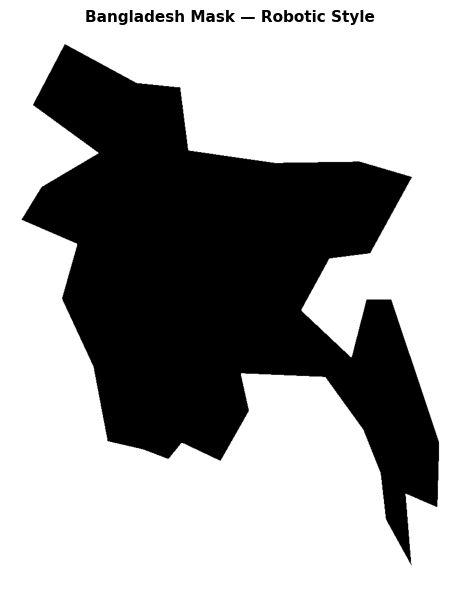

Unique words: 5906
Total tokens: 211044


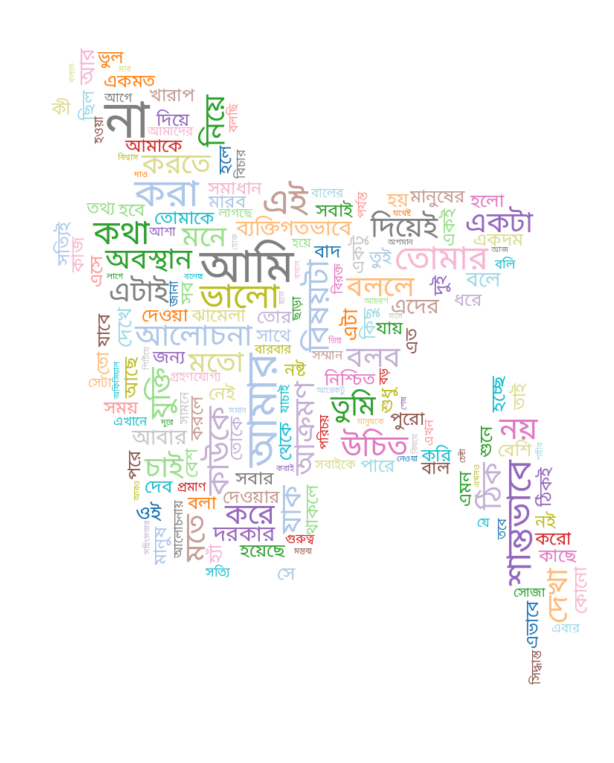


WORD CLOUD GENERATED SUCCESSFULLY
DataFrame      : final_train
Text column    : target_reply
Dataset shape  : (19453, 11)
Unique words   : 5906
Total tokens   : 211044
Map tolerance  : 0.018
Output         : /content/drive/MyDrive/toxicity/final data/train/figures/final_bd_shaped_wordcloud_mixed_robotic.png
Resolution     : 600 DPI


In [40]:
# ============================================================
# INSTALLATION
# ============================================================

# !pip install -q wordcloud scipy requests


# ============================================================
# IMPORTS
# ============================================================

import re
import requests
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.path import Path
from collections import Counter
from wordcloud import WordCloud


# ============================================================
# CONFIGURATION
# ============================================================

FONT = "/content/NotoSansBengali.ttf"

TOKEN_RE = re.compile(
    r"[\u0980-\u09FF]+|[A-Za-z]+"
)

W, H = 800, 1000

SIMPLIFY_TOLERANCE = 0.018


# ============================================================
# 1. AUTOMATICALLY FIND DATAFRAME
# ============================================================

if "final_train" in globals():

    df = final_train.copy()
    print("Using dataframe: final_train")

elif "combined" in globals():

    df = combined.copy()
    print("Using dataframe: combined")

else:

    raise NameError(
        "No suitable dataframe found. "
        "Please make sure final_train or combined exists."
    )


# ============================================================
# 2. AUTOMATICALLY FIND TEXT COLUMN
# ============================================================

possible_text_cols = [
    "target_reply",
    "reply",
    "text",
    "target_comment",
    "comment"
]

text_col = None

for col in possible_text_cols:

    if col in df.columns:

        text_col = col
        break


if text_col is None:

    raise ValueError(
        "No text column found.\n"
        f"Available columns are: {list(df.columns)}"
    )


print("Using text column:", text_col)
print("Dataset shape:", df.shape)


# ============================================================
# 3. DOWNLOAD BANGLADESH GEOJSON
# ============================================================

url = (
    "https://raw.githubusercontent.com/"
    "johan/world.geo.json/master/countries/BGD.geo.json"
)

response = requests.get(
    url,
    timeout=30
)

response.raise_for_status()

data = response.json()


# ============================================================
# 4. EXTRACT POLYGON RINGS
# ============================================================

def rings_from_geom(geom):

    if geom["type"] == "Polygon":

        return [
            geom["coordinates"][0]
        ]

    elif geom["type"] == "MultiPolygon":

        return [
            polygon[0]
            for polygon in geom["coordinates"]
        ]

    return []


rings = []

features = (
    data["features"]
    if data.get("type") == "FeatureCollection"
    else [data]
)


for feature in features:

    rings.extend(
        rings_from_geom(
            feature["geometry"]
        )
    )


# ============================================================
# 5. SIMPLIFY BOUNDARY
# ============================================================

def simplify_ring(points, tolerance=0.018):

    points = np.asarray(points)

    cleaned = [points[0]]

    for p in points[1:]:

        distance = np.linalg.norm(
            p - cleaned[-1]
        )

        if distance > tolerance:

            cleaned.append(p)

    cleaned = np.asarray(cleaned)

    return cleaned


simplified_rings = []

for ring in rings:

    simplified = simplify_ring(
        ring,
        tolerance=SIMPLIFY_TOLERANCE
    )

    if len(simplified) >= 3:

        simplified_rings.append(
            simplified
        )


# ============================================================
# 6. MAP EXTENT
# ============================================================

pts = np.vstack(
    simplified_rings
)

minx, miny = pts.min(axis=0)
maxx, maxy = pts.max(axis=0)


# ============================================================
# 7. CREATE GRID
# ============================================================

pad_x = 0.025
pad_y = 0.025

xs = np.linspace(
    minx - (maxx - minx) * pad_x,
    maxx + (maxx - minx) * pad_x,
    W
)

ys = np.linspace(
    maxy + (maxy - miny) * pad_y,
    miny - (maxy - miny) * pad_y,
    H
)

xx, yy = np.meshgrid(
    xs,
    ys
)

points = np.column_stack(
    [
        xx.ravel(),
        yy.ravel()
    ]
)


# ============================================================
# 8. CREATE BANGLADESH MASK
# ============================================================

inside = np.zeros(
    H * W,
    dtype=bool
)

for ring in simplified_rings:

    polygon = Path(
        ring,
        closed=True
    )

    inside |= polygon.contains_points(
        points
    )


inside = inside.reshape(
    H,
    W
)


# ============================================================
# 9. ROBOTIC / ANGULAR EDGE
# ============================================================

from scipy import ndimage


inside_robotic = ndimage.binary_erosion(
    inside,
    structure=np.ones((2, 2)),
    iterations=1
)


mask = np.full(
    (H, W),
    255,
    dtype=np.uint8
)

mask[inside_robotic] = 0


# ============================================================
# 10. PREVIEW MASK
# ============================================================

plt.figure(
    figsize=(5, 6)
)

plt.imshow(
    mask,
    cmap="gray"
)

plt.title(
    "Bangladesh Mask — Robotic Style",
    fontsize=11,
    fontweight="bold"
)

plt.axis("off")

plt.tight_layout()

plt.show()


# ============================================================
# 11. WORD FREQUENCY
# ============================================================

freq = Counter()

for text in df[text_col].astype(str):

    tokens = TOKEN_RE.findall(
        text.lower()
    )

    for word in tokens:

        if len(word) >= 2:

            freq[word] += 1


print(
    "Unique words:",
    len(freq)
)

print(
    "Total tokens:",
    sum(freq.values())
)


# ============================================================
# 12. GENERATE WORD CLOUD
# ============================================================

wc = WordCloud(

    width=W,

    height=H,

    background_color="white",

    mask=mask,

    contour_width=0,

    font_path=FONT,

    colormap="tab20",

    max_words=180,

    max_font_size=70,

    min_font_size=8,

    relative_scaling=0.4,

    collocations=False,

    prefer_horizontal=0.65,

    repeat=False,

    regexp=r"[\u0980-\u09FF]+|[A-Za-z]+",

    margin=3,

    random_state=42

).generate_from_frequencies(
    freq
)


# ============================================================
# 13. OUTPUT DIRECTORY
# ============================================================

if "FINAL_FIG_DIR" in globals():

    out_dir = FINAL_FIG_DIR

else:

    from pathlib import Path

    out_dir = Path("/content")

    print(
        "FINAL_FIG_DIR not found."
    )

    print(
        "Saving output to /content/"
    )


out_dir.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 14. OUTPUT PATH
# ============================================================

out_path = (
    out_dir
    / "final_bd_shaped_wordcloud_mixed_robotic.png"
)


# ============================================================
# 15. FINAL FIGURE
# ============================================================

plt.figure(
    figsize=(6, 7.5),
    facecolor="white"
)

plt.imshow(
    wc,
    interpolation="bilinear"
)

plt.axis("off")

plt.tight_layout(
    pad=0.2
)


# ============================================================
# 16. SAVE
# ============================================================

plt.savefig(

    out_path,

    dpi=600,

    bbox_inches="tight",

    facecolor="white",

    pad_inches=0.05
)

plt.show()


# ============================================================
# 17. SUMMARY
# ============================================================

print("\n" + "=" * 60)

print(
    "WORD CLOUD GENERATED SUCCESSFULLY"
)

print("=" * 60)

print(
    "DataFrame      :",
    "final_train" if "final_train" in globals()
    else "combined"
)

print(
    "Text column    :",
    text_col
)

print(
    "Dataset shape  :",
    df.shape
)

print(
    "Unique words   :",
    len(freq)
)

print(
    "Total tokens   :",
    sum(freq.values())
)

print(
    "Map tolerance  :",
    SIMPLIFY_TOLERANCE
)

print(
    "Output         :",
    out_path
)

print(
    "Resolution     : 600 DPI"
)

print("=" * 60)

Using dataframe: final_train
Dataset shape: (19453, 11)


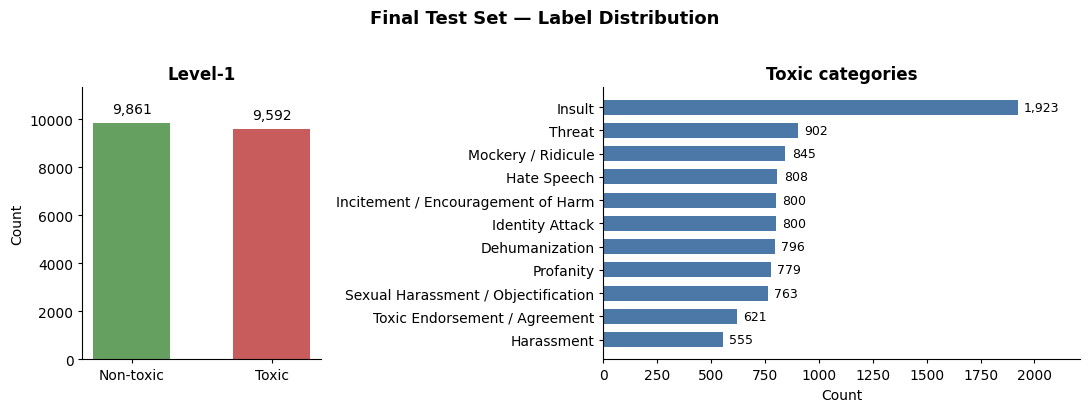

Saved -> /content/drive/MyDrive/toxicity/final data/train/figures/final_label_distribution_minimal.png


In [41]:
# =====================================================================
# Minimal Clean Figure — Label Distribution
# =====================================================================

import matplotlib.pyplot as plt
from pathlib import Path


# =====================================================================
# 1. SELECT DATAFRAME
# =====================================================================

if "final_test" in globals():

    df = final_test.copy()
    df_name = "final_test"

elif "combined" in globals():

    df = combined.copy()
    df_name = "combined"

elif "final_train" in globals():

    df = final_train.copy()
    df_name = "final_train"

else:

    raise NameError(
        "No suitable dataframe found. "
        "Please make sure final_test, final_train, or combined exists."
    )

print("Using dataframe:", df_name)
print("Dataset shape:", df.shape)


# =====================================================================
# 2. CHECK REQUIRED COLUMNS
# =====================================================================

required_cols = [
    "level_1_class",
    "toxicity_type"
]

missing_cols = [
    c for c in required_cols
    if c not in df.columns
]

if missing_cols:

    raise ValueError(
        f"Missing required columns: {missing_cols}\n"
        f"Available columns: {list(df.columns)}"
    )


# =====================================================================
# 3. FIGURE
# =====================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4),
    gridspec_kw={
        "width_ratios": [1, 2]
    }
)


# =====================================================================
# 4. LEFT — LEVEL 1
# =====================================================================

l1 = (
    df["level_1_class"]
    .value_counts()
    .reindex(
        ["Non-toxic", "Toxic"],
        fill_value=0
    )
)

bars = axes[0].bar(
    ["Non-toxic", "Toxic"],
    l1.values,
    color=["#66A061", "#C85C5C"],
    width=0.55,
    edgecolor="none"
)


axes[0].set_title(
    "Level-1",
    fontsize=12,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Count",
    fontsize=10
)


max_l1 = max(
    l1.values
) if len(l1.values) else 1

axes[0].set_ylim(
    0,
    max_l1 * 1.15
)


# Value labels

for i, v in enumerate(l1.values):

    axes[0].text(
        i,
        v + max_l1 * 0.03,
        f"{v:,}",
        ha="center",
        va="bottom",
        fontsize=10
    )


# Clean axes

axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

axes[0].spines["left"].set_linewidth(0.8)
axes[0].spines["bottom"].set_linewidth(0.8)

axes[0].tick_params(
    axis="both",
    length=3
)


# =====================================================================
# 5. RIGHT — TOXIC CATEGORIES
# =====================================================================

tox = (
    df.loc[
        df["level_1_class"].eq("Toxic"),
        "toxicity_type"
    ]
    .value_counts()
)


# Remove zero values

tox = tox[
    tox > 0
]


# Sort ascending so largest category appears at bottom

tox = tox.sort_values(
    ascending=True
)


# Horizontal bars

bars = axes[1].barh(
    tox.index,
    tox.values,
    color="#4C78A8",
    edgecolor="none",
    height=0.65
)


axes[1].set_title(
    "Toxic categories",
    fontsize=12,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Count",
    fontsize=10
)


# =====================================================================
# 6. VALUE LABELS
# =====================================================================

max_tox = (
    max(tox.values)
    if len(tox.values)
    else 1
)


for i, (label, value) in enumerate(
    tox.items()
):

    axes[1].text(
        value + max_tox * 0.015,
        i,
        f"{value:,}",
        va="center",
        fontsize=9
    )


# =====================================================================
# 7. CLEAN RIGHT AXIS
# =====================================================================

axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

axes[1].spines["left"].set_linewidth(0.8)
axes[1].spines["bottom"].set_linewidth(0.8)

axes[1].tick_params(
    axis="both",
    length=3
)


# Give labels some breathing room

if len(tox) > 0:

    axes[1].set_xlim(
        0,
        max_tox * 1.15
    )


# =====================================================================
# 8. FIGURE TITLE
# =====================================================================

fig.suptitle(
    "Final Test Set — Label Distribution",
    fontsize=13,
    fontweight="bold",
    y=1.02
)


# =====================================================================
# 9. LAYOUT
# =====================================================================

plt.tight_layout()


# =====================================================================
# 10. OUTPUT DIRECTORY
# =====================================================================

if "FINAL_FIG_DIR" in globals():

    out_dir = Path(FINAL_FIG_DIR)

else:

    out_dir = Path("/content")

    print(
        "FINAL_FIG_DIR not found. "
        "Saving to /content/"
    )


out_dir.mkdir(
    parents=True,
    exist_ok=True
)


# =====================================================================
# 11. SAVE
# =====================================================================

out_path = (
    out_dir
    / "final_label_distribution_minimal.png"
)


plt.savefig(
    out_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.05
)


plt.show()


# =====================================================================
# 12. CONFIRMATION
# =====================================================================

print(
    "Saved ->",
    out_path
)